# dev3 — Flock camera mapping: research milestones (repo datasets)

Same milestones, questions and ground rules as `dev2.ipynb`, rebuilt to run **only on the datasets that live in this
repo** (`data/raw/`, `data/external/`). dev2 called modules (`config`, `validate`, `history`, `figures_q1`,
`figures_q2`) and processed files (`flock_us_current.parquet`, `tract_analysis.parquet`, ...) that do not exist here,
so every step is done inline below. Nothing is written to disk.

**Three questions.** (1) Where are *mapped* Flock cameras and how has the mapping grown (V1–V3)? (2) Is mapped
camera density associated with community characteristics (V4–V6)? (3) Is it associated with county voting patterns
(V7–V9)?

**Ground rules.** OSM-mapped cameras are not all installed cameras. An OSM date is when a volunteer *mapped* a camera,
not when it was installed. Counts are **Flock-only**. Everything is cross-sectional or mapping history, so nothing here
can show causation.

**What changed from dev2 (inputs)**

| dev2 input | dev3 input (in repo) | Effect |
|---|---|---|
| `data/raw/flock_us_current.csv` (112,527 nodes) | `data/raw/flock_osm/osm_flock_us_locations_2026-10-30.csv` (112,830 nodes, newer edits) | Snapshot is a slightly different cohort; see M2.2 |
| `data/raw/flock_us_historical.csv` | `data/raw/flock_osm/flock_us_historical_2026-10-30.csv` | Same 112,527 rows |
| ACS 2024 national `.dat` bulk files (B01003, B19013) | `data/raw/census/...` per-table tract CSVs: B01003, B19013, **S1701 poverty, B03002 race** (2017 + 2024) | Tract level only; poverty and race now available |
| Census 1:500k state + tract cartographic files | `data/external/census_boundaries/`: TIGER 2024 tracts (50 states + DC) and counties | States come from the county file; no Puerto Rico tracts |
| Chicago 2023 crimes | — (not in repo) | **V5 replaced** by poverty / race (M6) |
| OSM history cache, Chicago attic counts, outside-strict-rule export, ways JSON | — (not in repo) | M2.2 / M3 checks that needed them are reduced |
| — | `data/raw/elections/`, `data/raw/finding_flock/`, `data/raw/atlas_of_surveillance/` | Finding Flock baseline can now be re-run (M1.2); elections ready for M7 |

| Milestone | Status |
|---|---|
| M1 — Baseline audit | done |
| M2 — Nationwide camera snapshot | done |
| M3 — OSM history dates | done (reduced: no history cache / attic data in repo) |
| M4 — V1–V3 | done |
| M5 — Tract analytical table | done (no crime data) |
| M6 — V4–V6 | done (V5 = poverty and race instead of crime) |
| M7 — County politics + procurement | done (procurement = Atlas of Surveillance proxy) |
| M8 — V7–V9 | done |
| M9 — Final QA | done |

In [1]:
import json
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import shapely
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, LogNorm
from scipy import stats

# geopandas warns when pyproj cannot load (it is blocked on some machines). Nothing below reprojects:
# joins run in lon/lat and the maps use a hand-written Albers projection, so the warning is harmless.
warnings.filterwarnings("ignore", category=UserWarning, message=".*(CRS|crs|pyproj|geographic).*")

pl.Config.set_tbl_cols(25)
pl.Config.set_tbl_rows(70)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(70)

# Colours: one blue ramp for magnitude, orange for the single highlight series, recessive greys for axes.
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.alpha": 1.0, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})

# Project root = the folder holding data/raw, wherever the notebook is run from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from cs418_flock_research.loaders.load_osm_history import load_osm_history
from cs418_flock_research.loaders.load_osm_locations import load_osm_locations

RAW, EXT = ROOT / "data" / "raw", ROOT / "data" / "external"
CENSUS = RAW / "census"
P = {
    "locations": RAW / "flock_osm" / "osm_flock_us_locations_2026-10-30.csv",
    "history": RAW / "flock_osm" / "flock_us_historical_2026-10-30.csv",
    "atlas": RAW / "atlas_of_surveillance" / "atlas_of_surveillance_2026-09-28.csv",
    "ff_city": RAW / "finding_flock" / "findingflock-cameras-by-city.csv",
    "ff_state": RAW / "finding_flock" / "findingflock-cameras-by-state.csv",
    "acs_pop": CENSUS / "population" / "2024" / "ACSDT5Y2024.B01003-Data.csv",
    "acs_income": CENSUS / "median_household_income" / "2024" / "ACSDT5Y2024.B19013-Data.csv",
    "acs_poverty": CENSUS / "poverty" / "2024" / "ACSST5Y2024.S1701-Data.csv",
    "acs_race": CENSUS / "race_ethnicity" / "2024" / "ACSDT5Y2024.B03002-Data.csv",
    "elections": RAW / "elections" / "presidential" / "countypres_2000-2024.csv",
    "tracts_2024": EXT / "census_boundaries" / "2024",
    "counties": EXT / "census_boundaries" / "counties" / "tl_2024_us_county.zip",
    "chicago_city": EXT / "chicago" / "chicago-city.geojson",
    "chicago_wards": EXT / "chicago" / "chicago-wards.geojson",
    "chicago_ward_income": EXT / "chicago" / "chicago-ward-income.csv",
}
missing = [k for k, v in P.items() if not v.exists()]
assert not missing, f"missing inputs: {missing}"
print("root:", ROOT)

root: C:\Users\awaid\OneDrive\Desktop\D\UIC\UIC_Fa26\CS418\cs418-flock-research


In [2]:
# --- shared helpers --------------------------------------------------------------------------------------------
STATES = {  # FIPS -> (USPS, name); 50 states, DC and the territories that appear in Census files
    "01": ("AL", "Alabama"), "02": ("AK", "Alaska"), "04": ("AZ", "Arizona"), "05": ("AR", "Arkansas"),
    "06": ("CA", "California"), "08": ("CO", "Colorado"), "09": ("CT", "Connecticut"), "10": ("DE", "Delaware"),
    "11": ("DC", "District of Columbia"), "12": ("FL", "Florida"), "13": ("GA", "Georgia"), "15": ("HI", "Hawaii"),
    "16": ("ID", "Idaho"), "17": ("IL", "Illinois"), "18": ("IN", "Indiana"), "19": ("IA", "Iowa"),
    "20": ("KS", "Kansas"), "21": ("KY", "Kentucky"), "22": ("LA", "Louisiana"), "23": ("ME", "Maine"),
    "24": ("MD", "Maryland"), "25": ("MA", "Massachusetts"), "26": ("MI", "Michigan"), "27": ("MN", "Minnesota"),
    "28": ("MS", "Mississippi"), "29": ("MO", "Missouri"), "30": ("MT", "Montana"), "31": ("NE", "Nebraska"),
    "32": ("NV", "Nevada"), "33": ("NH", "New Hampshire"), "34": ("NJ", "New Jersey"), "35": ("NM", "New Mexico"),
    "36": ("NY", "New York"), "37": ("NC", "North Carolina"), "38": ("ND", "North Dakota"), "39": ("OH", "Ohio"),
    "40": ("OK", "Oklahoma"), "41": ("OR", "Oregon"), "42": ("PA", "Pennsylvania"), "44": ("RI", "Rhode Island"),
    "45": ("SC", "South Carolina"), "46": ("SD", "South Dakota"), "47": ("TN", "Tennessee"), "48": ("TX", "Texas"),
    "49": ("UT", "Utah"), "50": ("VT", "Vermont"), "51": ("VA", "Virginia"), "53": ("WA", "Washington"),
    "54": ("WV", "West Virginia"), "55": ("WI", "Wisconsin"), "56": ("WY", "Wyoming"), "60": ("AS", "American Samoa"),
    "66": ("GU", "Guam"), "69": ("MP", "Northern Mariana Islands"), "72": ("PR", "Puerto Rico"),
    "78": ("VI", "U.S. Virgin Islands"),
}
STATE_DF = pl.DataFrame({"STATEFP": list(STATES), "state": [v[0] for v in STATES.values()],
                         "state_name": [v[1] for v in STATES.values()]})


def acs_number(col: str) -> pl.Expr:
    """ACS text -> float. '250,000+' -> 250001 (top-code), '2,500-' -> 2499, '-', '**', '(X)' etc. -> null."""
    s = pl.col(col).str.replace_all(",", "")
    return (pl.when(s.str.ends_with("+")).then(s.str.strip_suffix("+").cast(pl.Float64, strict=False) + 1)
            .when(s.str.ends_with("-") & (s.str.len_chars() > 1)).then(s.str.strip_suffix("-").cast(pl.Float64, strict=False) - 1)
            .otherwise(s.cast(pl.Float64, strict=False)).alias(col))


def read_acs(path: Path, cols: list[str], parse: bool = True) -> pl.DataFrame:
    """data.census.gov table download: row 0 repeats the labels; GEO_ID '1400000US' + 11-digit tract GEOID."""
    df = pl.read_csv(path, infer_schema_length=0, columns=["GEO_ID", *cols]).slice(1)
    df = df.with_columns(pl.col("GEO_ID").str.slice(9).alias("GEOID")).drop("GEO_ID")
    return df.with_columns([acs_number(c) for c in cols]) if parse else df


def assign_polygons(points: pl.DataFrame, polys: gpd.GeoDataFrame, keep: list[str], max_deg: float = 0.03) -> pl.DataFrame:
    """Point-in-polygon in lon/lat; points that fall outside every polygon (piers, coastal roads) go to the nearest
    polygon within `max_deg` degrees (about 2-3 km). Returns osm_id + `keep` + match ('within' / 'nearest' / null)."""
    pts = gpd.GeoDataFrame(points.select("osm_id").to_pandas(),
                           geometry=gpd.points_from_xy(points["lon"].to_numpy(), points["lat"].to_numpy()),
                           crs=polys.crs)
    polys = polys[keep + ["geometry"]]
    hit = gpd.sjoin(pts, polys, how="inner", predicate="within").drop_duplicates("osm_id")
    rest = pts[~pts["osm_id"].isin(hit["osm_id"])]
    near = gpd.sjoin_nearest(rest, polys, how="inner", max_distance=max_deg).drop_duplicates("osm_id")
    out = pd.concat([hit.assign(match="within"), near.assign(match="nearest")])[["osm_id", *keep, "match"]]
    return points.select("osm_id").join(pl.from_pandas(out), on="osm_id", how="left")


def albers(lon, lat, lon0, lat0, lat1, lat2, R=6371.0):
    """Spherical Albers equal-area (km). Used instead of pyproj; EPSG:5070 parameters for the lower 48."""
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    dl = np.radians((lon - lon0 + 180) % 360 - 180)
    p, p0, p1, p2 = (np.radians(v) for v in (lat, lat0, lat1, lat2))
    n = (np.sin(p1) + np.sin(p2)) / 2
    C = np.cos(p1) ** 2 + 2 * n * np.sin(p1)
    rho, rho0 = R * np.sqrt(C - 2 * n * np.sin(p)) / n, R * np.sqrt(C - 2 * n * np.sin(p0)) / n
    return rho * np.sin(n * dl), rho0 - rho * np.cos(n * dl)


def pooled_rate(cams: np.ndarray, pop: np.ndarray, reps: int = 1000, seed: int = 418):
    """All cameras / all residents * 10,000, with a 95% bootstrap interval over tracts."""
    rng = np.random.default_rng(seed)
    est, boots = cams.sum() / pop.sum() * 1e4, []
    for _ in range(reps // 100):
        idx = rng.integers(0, len(cams), (100, len(cams)))
        boots.append(cams[idx].sum(1) / pop[idx].sum(1) * 1e4)
    lo, hi = np.percentile(np.concatenate(boots), [2.5, 97.5])
    return est, lo, hi

## M1. Baseline audit

Goal: know exactly what is in the repo before building anything. Four parts: what is on disk (M1.1), whether the
Finding Flock baseline can now be re-run (M1.2), whether the inputs pass basic checks (M1.3), and what is still missing
(M1.4). Nothing in `data/` is changed.

### M1.1 What is on disk

In [3]:
def n_rows(path: Path):
    """Row count for CSVs (header excluded; ACS files also have a label row, counted here); None otherwise."""
    if path.suffix == ".csv":
        return pl.scan_csv(path, infer_schema_length=0).select(pl.len()).collect().item()
    return None

files = sorted(p for d in (RAW, EXT) for p in d.rglob("*") if p.is_file() and not p.name.startswith("."))
inventory = (
    pl.DataFrame({
        "folder": [str(p.parent.relative_to(ROOT)).replace("\\", "/") for p in files],
        "file": [p.name for p in files],
        "size_mb": [p.stat().st_size / 1e6 for p in files],
        "rows": [n_rows(p) for p in files],
    })
    # 102 tract zips: one line per folder instead of one per state
    .with_columns(pl.when(pl.col("file").str.contains(r"^tl_20\d\d_\d\d_tract\.zip$"))
                  .then(pl.lit("tl_*_tract.zip (one per state + DC)")).otherwise("file").alias("file"))
    .group_by("folder", "file", maintain_order=True)
    .agg(pl.len().alias("n_files"), pl.col("size_mb").sum().round(2), pl.col("rows").first())
)
inventory

folder,file,n_files,size_mb,rows
str,str,u32,f64,i64
"""data/external/census_boundaries/2017""","""tl_*_tract.zip (one per state + DC)""",51,370.92,null
"""data/external/census_boundaries/2024""","""tl_*_tract.zip (one per state + DC)""",51,417.32,null
"""data/external/census_boundaries/counties""","""tl_2024_us_county.zip""",1,83.91,null
"""data/external/chicago""","""chicago-city.geojson""",1,0.29,null
"""data/external/chicago""","""chicago-ward-income.csv""",1,0.0,50
"""data/external/chicago""","""chicago-wards.geojson""",1,2.04,null
"""data/raw/atlas_of_surveillance""","""atlas_of_surveillance_2026-09-28.csv""",1,8.56,15135
"""data/raw/census/median_household_income/2017""","""ACSDT5Y2017.B19013-Column-Metadata.csv""",1,0.0,4
"""data/raw/census/median_household_income/2017""","""ACSDT5Y2017.B19013-Data.csv""",1,6.43,74002


**What stands out (inventory)**

- The **two core Flock files** are in `data/raw/flock_osm/`: a nationwide snapshot (`osm_flock_us_locations`, 112,830
  nodes, with `brand`, camera tags and the full tag JSON) and the history file (`flock_us_historical`, 112,527 nodes).
  Unlike dev2's pair, they are **not the same cohort** (M2.2).
- Census inputs are **tract-level ACS 5-year tables for 2017 and 2024**: population (B01003), median household income
  (B19013), poverty (S1701) and race/ethnicity (B03002). Each CSV has a label row under the header, so a "row" count
  here is tracts + 1. There are no county/state ACS rows; state populations are summed from tracts.
- Boundaries are **TIGER 2024 and 2017 tracts** (one zip per state + DC, so no Puerto Rico) and the **TIGER 2024 county
  file** (which does include PR and the island areas).
- New compared with dev2: **county presidential returns 2000–2024** (for M7), the **Finding Flock** baseline tables, and
  Chicago ward boundaries + ward income. The Atlas of Surveillance is the same file (context only, never a Flock count).
- **Not here:** crime data, the OSM history cache, the attic/outside-rule exports and the `.meta.json` provenance (M1.4).

### M1.2 The Finding Flock baseline (`eda_findingflock.ipynb`) can now be re-run

dev2 could not re-execute the baseline because the Finding Flock CSVs were not on its machine. They are in the repo
now (`data/raw/finding_flock/`). The lessons dev2 took from it still apply:

| Part | What it showed | Reusable here? |
|---|---|---|
| D1 cameras per city | heavy right skew; a wall at 10 cameras | **Caveat only.** The city file drops every place with < 10 mapped cameras, so it has no zero group and cannot be a denominator. |
| D2 land area / density | density per sq mi is log-symmetric; tiny places inflate it | **Method.** Same small-denominator problem hits cameras per 10,000 residents in low-population tracts (V4). |
| D3 vendor mix | most listed-city cameras are Flock; big cities much less | **Caveat.** We count Flock only. |
| D4 cameras by state | CA, TX, GA, FL, IL lead (all vendors) | **Cross-check** for V3 (scope differs: all ALPR vs Flock). |
| R1 cameras vs area | cameras ∝ area^0.43 | **Lesson.** Raw counts mostly track size, so V3 needs normalisation. |
| R2 density by state | state is a strong confounder | **Lesson** for V4–V6 (compare within state). |
| R3 city-file coverage | only part of cameras are inside a listed city | **Lesson.** Start from complete boundary tables and keep zero-camera areas. |
| R4 Flock share vs size | the largest networks are the least Flock | **Lesson.** Total ALPR ≠ Flock. |

In [4]:
ff_city, ff_state = pl.read_csv(P["ff_city"]), pl.read_csv(P["ff_state"])
vendor_cols = ["flock", "motorola", "genetec", "leonardo", "neology", "other_vendor", "unknown_vendor"]
print("Finding Flock city file :", ff_city.shape, "| min cameras per listed city:", ff_city["cameras"].min())
print("Finding Flock state file:", ff_state.shape)
tot = ff_state.select(pl.col("cameras_statewide").sum(), pl.col("cameras_in_listed_cities").sum(), *[pl.col(c).sum() for c in vendor_cols])
print(f"cameras statewide (all vendors): {tot['cameras_statewide'][0]:,} | in listed cities: {tot['cameras_in_listed_cities'][0]:,} "
      f"({tot['cameras_in_listed_cities'][0] / tot['cameras_statewide'][0]:.1%})")
print("vendor columns sum to listed-city total:", sum(tot[c][0] for c in vendor_cols) == tot["cameras_in_listed_cities"][0],
      f"| Flock share of listed-city cameras: {tot['flock'][0] / tot['cameras_in_listed_cities'][0]:.1%}")

atlas = pl.read_csv(P["atlas"], infer_schema_length=0)
alpr = atlas.filter(pl.col("Technology").str.contains("(?i)license plate"))
print(f"\nAtlas of Surveillance: {atlas.height:,} agency-technology rows | ALPR rows: {alpr.height:,} "
      f"| ALPR rows naming Flock: {alpr.filter(pl.col('Vendor').str.contains('(?i)flock')).height:,} (context only, agency level)")

Finding Flock city file : (2422, 20) | min cameras per listed city: 10
Finding Flock state file: (52, 13)
cameras statewide (all vendors): 145,223 | in listed cities: 96,901 (66.7%)
vendor columns sum to listed-city total: True | Flock share of listed-city cameras: 79.4%

Atlas of Surveillance: 15,135 agency-technology rows | ALPR rows: 4,094 | ALPR rows naming Flock: 2,624 (context only, agency level)


### M1.3 Input validation

dev2 ran `validate.run_all()`, which does not exist in this repo. `run_checks()` below re-implements the same checks
on the repo files: required columns, unique ids, coordinate ranges, the manufacturer filter, nulls, date ordering,
the snapshot ↔ history cohort, and the ACS and election tables. `fail` means fix before use; `warn` means worth knowing
and is dealt with below.

In [5]:
snap_raw = load_osm_locations(P["locations"])
hist_raw = load_osm_history(P["history"])

TS_FMT = "%Y-%m-%dT%H:%M:%S%.f%z"
hist = hist_raw.with_columns(
    [pl.col(c).str.to_datetime(TS_FMT).dt.convert_time_zone("UTC") for c in ["last_edit", "first_insert_date", "first_tagged_date"]]
)
snap_ts = snap_raw.with_columns(pl.col("timestamp").str.to_datetime("%Y-%m-%dT%H:%M:%SZ", time_zone="UTC"))

def run_checks() -> pl.DataFrame:
    rows = []
    def add(dataset, check, value, ok=True, warn=False):
        rows.append({"dataset": dataset, "check": check, "value": str(value),
                     "status": "fail" if not ok else ("warn" if warn else "ok")})

    # --- OSM snapshot ------------------------------------------------------------------------
    s, name = snap_ts, "osm_locations"
    need = {"osm_type", "osm_id", "lat", "lon", "timestamp", "version", "man_made", "surveillance_type", "manufacturer", "brand", "operator"}
    add(name, "required columns present", "all" if need <= set(s.columns) else sorted(need - set(s.columns)), need <= set(s.columns))
    add(name, "rows", s.height)
    add(name, "duplicate (osm_type, osm_id)", s.select(pl.struct("osm_type", "osm_id").is_duplicated().sum()).item(),
        s.select(pl.struct("osm_type", "osm_id").is_duplicated().sum()).item() == 0)
    add(name, "osm_type values", s["osm_type"].unique().to_list(), warn=s["osm_type"].n_unique() == 1)
    bad = s.filter(~pl.col("lat").is_between(-90, 90) | ~pl.col("lon").is_between(-180, 180)).height
    add(name, "lat/lon outside valid range", bad, bad == 0)
    out_us = s.filter(~(pl.col("lat").is_between(13, 72) & (pl.col("lon").is_between(-180, -64) | pl.col("lon").is_between(144, 146)))).height
    add(name, "points outside US bounding boxes", out_us, warn=out_us > 0)
    shared = s.filter(pl.struct("lat", "lon").is_duplicated()).height
    add(name, "rows sharing an exact lat/lon with another row", shared, warn=shared > 0)
    nf = s.filter(~pl.col("manufacturer").str.contains("(?i)flock")).height
    add(name, "manufacturer without 'flock'", nf, nf == 0)
    add(name, "distinct manufacturer strings", s["manufacturer"].n_unique(), warn=s["manufacturer"].n_unique() > 1)
    add(name, "brand set / brand without 'flock'", f"{s['brand'].drop_nulls().len()} / {s.filter(~pl.col('brand').str.contains('(?i)flock')).height}",
        warn=s.filter(~pl.col("brand").str.contains("(?i)flock")).height > 0)
    add(name, "operator null", s["operator"].null_count(), warn=True)
    add(name, "man_made values", s["man_made"].unique().to_list(), s["man_made"].n_unique() == 1)
    add(name, "surveillance_type values", s["surveillance_type"].unique().to_list(), s["surveillance_type"].n_unique() == 1)
    lo, hi = s["timestamp"].min(), s["timestamp"].max()
    add(name, "last-edit timestamp range", f"{lo:%Y-%m-%d} .. {hi:%Y-%m-%d}")
    add(name, "newest edit later than file-name date (2026-10-30)", f"{hi:%Y-%m-%d %H:%M}", warn=hi.date().isoformat() > "2026-10-30")

    # --- OSM history ---------------------------------------------------------------------------
    h, name = hist, "osm_history"
    need = {"osm_id", "lat", "lon", "manufacturer", "operator", "version", "last_edit", "history_ok",
            "first_insert_date", "first_insert_version", "first_tagged_date", "first_tagged_version"}
    add(name, "required columns present", "all" if need <= set(h.columns) else sorted(need - set(h.columns)), need <= set(h.columns))
    add(name, "rows", h.height)
    add(name, "duplicate osm_id", h["osm_id"].is_duplicated().sum(), h["osm_id"].is_duplicated().sum() == 0)
    add(name, "osm_type column present (composite id)", "osm_type" in h.columns, warn="osm_type" not in h.columns)
    add(name, "history_ok != true", h.filter(~pl.col("history_ok")).height, h.filter(~pl.col("history_ok")).height == 0)
    nd = {c: h[c].null_count() for c in ["first_insert_date", "first_tagged_date", "last_edit"] if h[c].null_count()}
    add(name, "null dates", nd or 0, not nd)
    order = h.filter((pl.col("first_tagged_date") < pl.col("first_insert_date")) | (pl.col("first_tagged_date") > pl.col("last_edit"))).height
    add(name, "tagged before created / after last edit", order, order == 0)
    v1 = h.filter((pl.col("first_tagged_version") == 1) & (pl.col("first_tagged_date") != pl.col("first_insert_date"))).height
    add(name, "tagged in v1 but tagged date != created date", v1, v1 == 0)
    add(name, "first visible version > 1 (hidden early versions)", h.filter(pl.col("first_insert_version") > 1).height,
        warn=h.filter(pl.col("first_insert_version") > 1).height > 0)
    add(name, "manufacturer without 'flock'", h.filter(~pl.col("manufacturer").str.contains("(?i)flock")).height,
        h.filter(~pl.col("manufacturer").str.contains("(?i)flock")).height == 0)

    # --- snapshot <-> history cohort ------------------------------------------------------------
    a, b = set(s["osm_id"]), set(h["osm_id"])
    add("cohort", "ids in snapshot and history", len(a & b))
    add("cohort", "ids only in snapshot (no history date)", len(a - b), warn=len(a - b) > 0)
    add("cohort", "ids only in history (gone from snapshot)", len(b - a), warn=len(b - a) > 0)

    # --- ACS 2024 tract tables -------------------------------------------------------------------
    for key, col in [("acs_pop", "B01003_001E"), ("acs_income", "B19013_001E"), ("acs_poverty", "S1701_C03_001E"), ("acs_race", "B03002_001E")]:
        t = read_acs(P[key], [col], parse=False)
        add(key, "tract rows", t.height)
        add(key, "duplicate GEOID / not 11 digits", f"{t['GEOID'].is_duplicated().sum()} / {t.filter(pl.col('GEOID').str.len_chars() != 11).height}",
            t["GEOID"].is_duplicated().sum() == 0)
        n_missing = t.select(acs_number(col).is_null().sum()).item()
        add(key, f"{col} with no estimate", n_missing, warn=n_missing > 0)
        if key == "acs_income":
            add(key, "top-coded 250,000+ / bottom-coded 2,500-",
                f"{t.filter(pl.col(col) == '250,000+').height} / {t.filter(pl.col(col) == '2,500-').height}", warn=True)

    # --- elections -------------------------------------------------------------------------------
    el = pl.read_csv(P["elections"], infer_schema_length=0).filter(pl.col("year") == "2024")
    add("elections_2024", "rows / counties", f"{el.height:,} / {el['county_fips'].n_unique():,}")
    no_total = el.group_by("state_po").agg((pl.col("mode") == "TOTAL").any().alias("t")).filter(~pl.col("t"))["state_po"].to_list()
    add("elections_2024", "states without a TOTAL mode row (must sum modes)", sorted(no_total), warn=bool(no_total))
    return pl.DataFrame(rows)

checks = run_checks()
print(checks["status"].value_counts(sort=True))
checks

shape: (2, 2)
┌────────┬───────┐
│ status ┆ count │
│ ---    ┆ ---   │
│ str    ┆ u32   │
╞════════╪═══════╡
│ ok     ┆ 29    │
│ warn   ┆ 14    │
└────────┴───────┘


dataset,check,value,status
str,str,str,str
"""osm_locations""","""required columns present""","""all""","""ok"""
"""osm_locations""","""rows""","""112830""","""ok"""
"""osm_locations""","""duplicate (osm_type, osm_id)""","""0""","""ok"""
"""osm_locations""","""osm_type values""","""['node']""","""warn"""
"""osm_locations""","""lat/lon outside valid range""","""0""","""ok"""
"""osm_locations""","""points outside US bounding boxes""","""0""","""ok"""
"""osm_locations""","""rows sharing an exact lat/lon with another row""","""1877""","""warn"""
"""osm_locations""","""manufacturer without 'flock'""","""0""","""ok"""
"""osm_locations""","""distinct manufacturer strings""","""15""","""warn"""


**What stands out (validation)**

- **No failures.** Ids are unique, every coordinate is valid and inside the US boxes, every manufacturer string contains
  "flock", and the history dates are internally consistent (no nulls, no first-tagged date before creation or after
  the last edit, every version-1 tag has identical creation and tagged dates).
- **New warning vs dev2: the two OSM files are different pulls.** 112,124 ids are in both, 706 only in the snapshot and
  403 only in the history. The snapshot's newest edit is **2026-11-05**, so its file-name date (2026-10-30) is not its
  retrieval date.
- ACS income has **no estimate for 1,554 tracts** (553 top-coded at $250,000+, 9 bottom-coded at $2,500−); poverty has
  none for 1,044. Population is complete. These stay null and are reported in M5.
- 2024 election returns: several states report only by vote mode (no `TOTAL` row), so M7 must sum modes per county.

In [6]:
# --- manufacturer and brand spellings (M2 needs a normalisation rule) ---------------------------------------
snap_raw.group_by("manufacturer", "brand").len().sort("len", descending=True)

manufacturer,brand,len
str,str,u32
"""Flock Safety""",null,111914
"""Flock Group Inc.""","""Flock Safety""",465
"""Flock Safety""","""Flock Safety""",307
"""Flock""",null,57
"""Flock Safety Inc""","""Flock Safety""",44
"""Flock Group Inc.""",null,11
"""Flock Safety""","""Flock""",11
"""FlockSafety""",null,4
"""flock""",null,3


In [7]:
# --- exact duplicate coordinates ------------------------------------------------------------------------------
same_xy = (
    snap_raw.group_by("lat", "lon")
    .agg(pl.len().alias("nodes_here"), pl.col("user").n_unique().alias("distinct_mappers"),
         pl.col("direction").n_unique().alias("distinct_directions"))
    .filter(pl.col("nodes_here") > 1)
)
print("locations with > 1 node   :", same_xy.height, "| rows involved:", same_xy["nodes_here"].sum())
print("  ...mapped by > 1 user   :", same_xy.filter(pl.col("distinct_mappers") > 1).height)
print("  ...all one direction    :", same_xy.filter(pl.col("distinct_directions") == 1).height)
same_xy["nodes_here"].value_counts().sort("nodes_here")

locations with > 1 node   : 884 | rows involved: 1877
  ...mapped by > 1 user   : 46
  ...all one direction    : 518


nodes_here,count
u32,u32
2,809
3,48
4,21
5,5
6,1


In [8]:
# --- operator coverage and private operators ------------------------------------------------------------------
print(f"operator null: {snap_raw['operator'].null_count():,} of {snap_raw.height:,} ({snap_raw['operator'].null_count() / snap_raw.height:.1%})")
snap_raw["operator"].drop_nulls().value_counts(sort=True).head(12)

operator null: 99,134 of 112,830 (87.9%)


operator,count
str,u32
"""Lowe's""",1591
"""The Home Depot""",1115
"""California Highway Patrol (CHP)""",399
"""San Francisco Police Department""",386
"""Detroit Police Department""",229
"""Flock Safety""",197
"""Simon Property Group""",127
"""Irvine Police Department""",122
"""Las Vegas Metropolitan Police Department""",106


In [9]:
# --- when does Flock tagging start? ---------------------------------------------------------------------------
CUTOFF = pl.datetime(2024, 11, 1, time_zone="UTC")
print("earliest first_tagged_date     :", hist["first_tagged_date"].min())
print("earliest node creation         :", hist["first_insert_date"].min())
print("nodes created before Nov 2024  :", hist.filter(pl.col("first_insert_date") < CUTOFF).height)
print("nodes Flock-tagged after v1    :", hist.filter(pl.col("first_tagged_version") > 1).height)
print("nodes still at version 1       :", hist.filter(pl.col("version") == 1).height)

earliest first_tagged_date     : 2024-11-03 03:04:15+00:00
earliest node creation         : 2007-09-05 12:27:31+00:00
nodes created before Nov 2024  : 657
nodes Flock-tagged after v1    : 3876
nodes still at version 1       : 88391


### Anomaly table

| # | What it is | Rows affected | What we do |
|---|---|---|---|
| A1 | **Node-only.** `osm_type` is always `node`; the history file has no `osm_type` at all. | all | Label the dataset node-only. Composite id = (`node`, `osm_id`). |
| A2 | 15 manufacturer spellings plus a `brand` tag on 829 rows. 111,914 rows are plain `Flock Safety`; a few name **two vendors** (`;Motorola Solutions`, `;PlateSmart…`, `brand=Motorola Solutions`) or carry a note. | ~600 non-standard | **M2:** normalisation rule; multi-vendor strings flagged ambiguous and not counted. |
| A3 | Several nodes at the **exact same coordinates**: 1,877 rows at 884 spots (up to 6 at one), almost all by one mapper (46 spots involve > 1 user). | 1,877 rows | **Kept**, flagged. Most likely several cameras on one pole. |
| A4 | **Operator is null on 87.9%** of cameras, and the top named operators are **private retailers** (Lowe's 1,591, The Home Depot 1,115, Simon Property Group 127). | 99,134 null | **Left.** Counts mean *all mapped Flock cameras*, not police cameras. |
| A5 | **No camera is Flock-tagged before 2024-11-03**, though 657 nodes existed earlier under other tags (3,876 got the Flock tags after version 1). | whole time series | **M3.2.** V2 starts Nov 2024 and says why. |
| A6 | ACS income missing for 1,554 tracts, poverty for 1,044. | tracts | **Kept as null**, never filled. |
| A7 | **Snapshot ≠ history cohort** (706 / 403 ids differ; snapshot edits run to 2026-11-05). | ~1% | **M2.2.** Snapshot for counts, history for dates. |

(dev2's "199 cameras with no state, all in Puerto Rico" does not recur: the county file used here covers PR and USVI.)

### M1.4 Missing inputs for later milestones

In [10]:
needs = [
    ("Census tract boundaries (TIGER 2024, 50 states + DC)", "V4, V6", P["tracts_2024"]),
    ("Census county boundaries (TIGER 2024)", "V1, V3, V7, V8", P["counties"]),
    ("State boundaries", "V1, V3", None),
    ("Puerto Rico / island-area tract boundaries", "V4 (PR cameras)", None),
    ("ACS 2024 poverty (S1701) and race/ethnicity (B03002)", "V5 (substitute), V6", P["acs_poverty"]),
    ("County presidential returns 2000-2024 (MIT Election Lab)", "V7, V8", P["elections"]),
    ("Chicago reported crimes (pre-period)", "V5 (original)", None),
    ("OSM history cache / attic counts / outside-strict-rule export", "M3 re-verification, H4 sensitivity", None),
    ("Municipal Flock procurement decisions", "V9", None),
]
pl.DataFrame({"input": [n for n, _, _ in needs], "needed for": [u for _, u, _ in needs],
              "in repo": ["yes" if p is not None and p.exists() else "no" for *_, p in needs]})

input,needed for,in repo
str,str,str
"""Census tract boundaries (TIGER 2024, 50 states + DC)""","""V4, V6""","""yes"""
"""Census county boundaries (TIGER 2024)""","""V1, V3, V7, V8""","""yes"""
"""State boundaries""","""V1, V3""","""no"""
"""Puerto Rico / island-area tract boundaries""","""V4 (PR cameras)""","""no"""
"""ACS 2024 poverty (S1701) and race/ethnicity (B03002)""","""V5 (substitute), V6""","""yes"""
"""County presidential returns 2000-2024 (MIT Election Lab)""","""V7, V8""","""yes"""
"""Chicago reported crimes (pre-period)""","""V5 (original)""","""no"""
"""OSM history cache / attic counts / outside-strict-rule export""","""M3 re-verification, H4 sensitivity""","""no"""
"""Municipal Flock procurement decisions""","""V9""","""no"""


| Input | Status / plan |
|---|---|
| State boundaries | **Derived**: every camera is joined to the county file, which carries `STATEFP`; V1 outlines are counties dissolved by state |
| PR / island-area tracts | **Not in repo.** PR has ACS rows but no tract boundaries, so PR cameras get a state but no tract |
| Chicago crimes | **Not in repo.** V5 is replaced by tract poverty and race/ethnicity (both now in the repo) |
| OSM history cache, attic counts, outside-rule export, ways | **Not in repo.** dev2's independent re-check and the H4 sensitivity layer cannot be reproduced offline (see M3) |
| Procurement | **BLOCKED** — no dataset exists (unchanged from dev2) |

## M1 summary

- **Changed:** nothing on disk. dev2's `config` / `validate` steps are inlined (`P`, `run_checks()`).
- **Passed:** see the `fail` count above.
- **Open:** node-only scope, manufacturer normalisation, the snapshot ↔ history cohort gap, the Nov 2024 tagging floor.
- **Blocked:** V9 (no procurement data); original V5 (no crime data in repo).

## M2. Nationwide mapped Flock camera snapshot

Goal: one validated table, **one row per mapped Flock camera node**, with scope, tag policy and a manufacturer rule.
dev2 built `flock_us_current.parquet` with `snapshot.py`; here it is built inline as `snap`.

**Decision: the repo's locations file is the snapshot.** It is a newer pull than dev2's (edits up to early
November 2026, even though the file name says 2026-10-30), so it is not the exact cohort the history dates were looked
up for. Cameras without a history row are kept in every *count* (V1, V3, V4–V6) and are only missing from the
*growth curve* (V2), which uses the history file's own cohort.

### M2.1 Provenance (what the file itself tells us)

In [11]:
key_counts = pl.Series([k for d in snap_raw["all_tags"].head(20000).to_list() for k in json.loads(d)]).value_counts(sort=True)
print("rows                 :", f"{snap_raw.height:,}")
print("osm_type             :", snap_raw["osm_type"].unique().to_list(), "(node-only; ways/relations are not in the file)")
print("tag filter (implied) : man_made =", snap_raw["man_made"].unique().to_list(), "| surveillance:type =",
      snap_raw["surveillance_type"].unique().to_list(), "| every manufacturer contains 'flock'")
print("edit timestamps      :", snap_ts["timestamp"].min(), "->", snap_ts["timestamp"].max())
print("query / retrieval log: not in repo (no .meta.json); dated by file name and newest edit")
print("\nmost common tag keys (first 20,000 rows):")
key_counts.head(15)

rows                 : 112,830
osm_type             : ['node'] (node-only; ways/relations are not in the file)
tag filter (implied) : man_made = ['surveillance'] | surveillance:type = ['ALPR'] | every manufacturer contains 'flock'
edit timestamps      : 2024-11-17 02:09:40+00:00 -> 2026-11-05 23:43:35+00:00
query / retrieval log: not in repo (no .meta.json); dated by file name and newest edit

most common tag keys (first 20,000 rows):


,count
str,u32
"""man_made""",20000
"""manufacturer""",20000
"""surveillance:type""",20000
"""camera:type""",19426
"""manufacturer:wikidata""",18915
"""direction""",18797
"""surveillance""",15276
"""surveillance:zone""",14848
"""camera:mount""",11846


### M2.2 Snapshot vs history cohort (replaces dev2's live smoke test)

dev2 checked the snapshot against live Overpass and an older export. Both need the network or files not in the repo,
so instead we compare the two OSM files the repo does have.

In [12]:
both = snap_raw.join(hist_raw.select("osm_id", pl.col("lat").alias("lat_h"), pl.col("lon").alias("lon_h"),
                                     pl.col("version").alias("version_h")), on="osm_id", how="inner")
only_snap = snap_ts.filter(~pl.col("osm_id").is_in(hist_raw["osm_id"].implode()))
only_hist = hist.filter(~pl.col("osm_id").is_in(snap_raw["osm_id"].implode()))
print("in both files                   :", f"{both.height:,}")
print("only in snapshot (newer)        :", f"{only_snap.height:,}", "| their edit times:", only_snap["timestamp"].min(), "->", only_snap["timestamp"].max())
print("only in history (since removed) :", f"{only_hist.height:,}", "| last edit before removal:", only_hist["last_edit"].max())
print("in both, version changed        :", both.filter(pl.col("version") != pl.col("version_h")).height)
print("in both, moved                  :", both.filter((pl.col("lat") != pl.col("lat_h")) | (pl.col("lon") != pl.col("lon_h"))).height)
print(f"net drift                       : {snap_raw.height - hist_raw.height:+,} nodes ({(snap_raw.height - hist_raw.height) / hist_raw.height:+.2%})")

in both files                   : 112,124
only in snapshot (newer)        : 706 | their edit times: 2026-10-30 19:38:32+00:00 -> 2026-11-05 23:43:35+00:00
only in history (since removed) : 403 | last edit before removal: 2026-10-30 19:26:28+00:00
in both, version changed        : 136
in both, moved                  : 70
net drift                       : +303 nodes (+0.27%)


**What stands out (cohort).** The repo snapshot is the history cohort **plus about a week of editing**: 706 cameras were
added (all edited after 2026-10-30 19:38), 403 were deleted or re-tagged, 136 changed version and 70 moved. Net drift is
+303 nodes (+0.27%), the same order as dev2's live drift (+0.23% in two days). So the map is actively edited and every
figure names its source date. The 706 newer cameras have no history date, which only matters for V2.

### M2.3 Manufacturer normalisation

Same rule as dev2's `manufacturer_status()`: `exact` = "Flock Safety"; `spelling_variant` = the same company with only
case, spacing or legal suffix different; `annotated` = "Flock Safety" plus a note; `ambiguous` = names a second vendor
(in `manufacturer` **or** `brand`, which this file has and dev2's did not) or a name that is not the company's.
Ambiguous rows are kept but get `is_flock = false` and are **left out of every Flock count**.

In [13]:
SAME_COMPANY = {"flocksafety", "flock", "flockgroupinc.", "flockgroupinc", "flocksafetyinc", "flocksafetyinc."}

def manufacturer_status(manufacturer: str | None, brand: str | None = None) -> str:
    if manufacturer is None:
        return "missing"
    low = manufacturer.casefold().strip()
    if ";" in low or any(v in low for v in ("motorola", "platesmart", "genetec", "vigilant")):
        return "ambiguous"
    if brand is not None and "flock" not in brand.casefold():
        return "ambiguous"
    if low.replace(" ", "") in SAME_COMPANY:
        return "exact" if manufacturer == "Flock Safety" else "spelling_variant"
    if low.startswith("flock safety"):
        return "annotated"
    return "ambiguous"

def add_status(df: pl.DataFrame, brand_col: str | None) -> pl.DataFrame:
    cols = ["manufacturer"] + ([brand_col] if brand_col else [])
    pairs = df.select(cols).unique()
    pairs = pairs.with_columns(pl.Series("manufacturer_status", [
        manufacturer_status(r["manufacturer"], r.get(brand_col) if brand_col else None) for r in pairs.iter_rows(named=True)]))
    return (df.join(pairs, on=cols, how="left", nulls_equal=True)
              .with_columns((pl.col("manufacturer_status") != "ambiguous").alias("is_flock")))

snap = add_status(snap_ts, "brand")
(snap.group_by("manufacturer_status")
     .agg(pl.len().alias("rows"), pl.struct("manufacturer", "brand").unique().alias("raw strings (manufacturer, brand)"))
     .sort("rows", descending=True))

manufacturer_status,rows,"raw strings (manufacturer, brand)"
str,u32,list[struct[2]]
"""exact""",112233,"[{""Flock Safety"",null}, {""Flock Safety"",""Flock Safety""}, … {""Flock Safety"",""Flock safety""}]"
"""spelling_variant""",587,"[{""FlockSafety"",null}, {""Flock Group Inc."",""Flock Safety""}, … {""Flock safety"",null}]"
"""ambiguous""",7,"[{""Flock Safety"",""Motorola Solutions""}, {""Flock Safety;Motorola Solutions"",null}, … {""Flock Safety;PlateSmart/CyclopsTchnlgs"",null}]"
"""annotated""",3,"[{""Flock Safety (installation in progress)"",null}, {""Flock Safety + Clear Creek District"",null}]"


### M2.4 State and county assignment, and validation of the processed snapshot

dev2 joined cameras to Census 1:500k **state** outlines. The repo has the TIGER 2024 **county** file instead
(which includes Puerto Rico and the island areas), so each camera gets a county, and its state comes from the county's
`STATEFP`. Joins are point-in-polygon in lon/lat (NAD83 vs WGS84 differ by < 2 m); cameras just outside the
shoreline-clipped outline go to the nearest county within 0.03°.

In [14]:
counties = gpd.read_file(f"zip://{P['counties'].as_posix()}", columns=["STATEFP", "COUNTYFP", "GEOID", "NAME", "ALAND"])
cty = assign_polygons(snap, counties.rename(columns={"GEOID": "county_geoid", "NAME": "county_name"}),
                      ["STATEFP", "county_geoid", "county_name"])
snap = (snap.join(cty.rename({"match": "county_match"}), on="osm_id", how="left")
            .join(STATE_DF, on="STATEFP", how="left"))

flock = snap.filter("is_flock")
print("rows / counted as Flock        :", f"{snap.height:,} / {flock.height:,}")
print("duplicate (osm_type, osm_id)   :", snap.select(pl.struct("osm_type", "osm_id").is_duplicated().sum()).item())
print("lat/lon out of range           :", snap.filter(~pl.col("lat").is_between(-90, 90) | ~pl.col("lon").is_between(-180, 180)).height)
print("nulls by column                :", {c: n for c, n in snap.drop("brand", "camera_direction", "direction", "camera_type", "camera_mount",
                                                                       "camera_angle", "surveillance_zone").null_count().row(0, named=True).items() if n})
print("county match                   :", flock["county_match"].value_counts(sort=True).rows())
assigned = flock.filter(pl.col("state").is_not_null()).height
print(f"reconciliation                 : {assigned:,} assigned + {flock.height - assigned} unassigned = {flock.height:,}")

rows / counted as Flock        : 112,830 / 112,823
duplicate (osm_type, osm_id)   : 0
lat/lon out of range           : 0
nulls by column                : {'operator': 99134}
county match                   : [('within', 112823)]
reconciliation                 : 112,823 assigned + 0 unassigned = 112,823


In [15]:
by_state = flock.group_by("STATEFP", "state", "state_name").len("cameras").sort("cameras", descending=True)
print("states/territories with cameras:", by_state.height)
by_state.drop("STATEFP")

states/territories with cameras: 53


state,state_name,cameras
str,str,u32
"""CA""","""California""",16513
"""TX""","""Texas""",15782
"""GA""","""Georgia""",9297
"""FL""","""Florida""",7176
"""OH""","""Ohio""",6097
"""IL""","""Illinois""",5489
"""NC""","""North Carolina""",3392
"""IN""","""Indiana""",3385
"""TN""","""Tennessee""",3126


**What stands out (snapshot)**

- **112,830 nodes, 112,823 counted as Flock.** 7 ambiguous rows are excluded: 4 name a second vendor in `manufacturer`
  (Motorola ×3, PlateSmart ×1), 1 has `brand=Motorola Solutions`, and 2 say "Flock Surveillance". 587 spelling variants
  and 3 annotated strings are kept.
- **Every Flock camera is inside a county** (112,823 `within`, none needed the nearest-county fallback). TIGER county
  polygons include coastal water, unlike dev2's shoreline-clipped 1:500k outlines, so piers and bridges fall inside.
  That includes **146 in Puerto Rico and 58 in the US Virgin Islands**.
- Raw counts lead with California (16,513), Texas (15,782), Georgia (9,297), Florida (7,176) and Ohio (6,097), within
  ~1% of dev2's numbers. These mostly reflect population; V3 normalises.

### M2 summary

- **Changed:** nothing on disk. Snapshot = repo locations file, manufacturer rule extended to `brand`, state/county from
  TIGER 2024 counties.
- **Passed:** unique composite ids, valid coordinates, manufacturer rule applied, state counts reconcile (0 unassigned).
- **Limitations:** node-only; mapped ≠ installed; no retrieval log; operator mostly missing and partly private;
  snapshot is about a week newer than the history cohort.

## M3. Historical first-appearance dates

Goal: for every camera in the history file, clearly defined OSM dates and an honest answer to *what period does the
history actually cover?* The repo's history file uses different column names from dev2's processed parquet:

| repo column | dev2 name | meaning (none of these is an installation date) |
|---|---|---|
| `first_insert_date` | `osm_object_created_at` | earliest *visible* version of the node |
| `first_tagged_date` | `first_flock_alpr_tagged_at` | first version tagged `man_made=surveillance` + `surveillance:type=ALPR` + `manufacturer~/flock/i` |
| `last_edit` | `osm_last_modified_at` | current version |

**Cohort:** first appearances of the 112,527 cameras mapped when the history was pulled (2026-10-30). Cameras mapped
and later deleted are not in it, and neither are the newer cameras only in the snapshot (M2.2).

### M3.1 Are the dates consistent?

dev2 also re-downloaded 90 node histories and reproduced the dates exactly. That cache (`data/raw/osm_history_cache/`)
is not in the repo; the optional cell after this one repeats a small version of the check against the live OSM API.

In [16]:
hist = add_status(hist, None)
print("rows                                   :", f"{hist.height:,}")
print("history_ok = true                      :", f"{hist['history_ok'].sum():,}")
print("missing dates                          :", sum(hist[c].null_count() for c in ["first_insert_date", "first_tagged_date", "last_edit"]))
print("tagged before created / after last edit:", hist.filter((pl.col("first_tagged_date") < pl.col("first_insert_date"))
                                                              | (pl.col("first_tagged_date") > pl.col("last_edit"))).height)
v1 = hist.filter(pl.col("first_tagged_version") == 1)
print("tagged in v1 with tagged != created    :", v1.filter(pl.col("first_tagged_date") != pl.col("first_insert_date")).height, "of", f"{v1.height:,}")
print("nodes with hidden early versions       :", hist.filter(pl.col("first_insert_version") > 1).height)
later = hist.filter(pl.col("first_tagged_version") > 1).with_columns(
    ((pl.col("first_tagged_date") - pl.col("first_insert_date")).dt.total_days()).alias("gap_days"))
print(f"tagged in first version                : {v1.height:,} ({v1.height / hist.height:.1%})")
print(f"tagged later                           : {later.height:,} | median gap {later['gap_days'].median():.0f} days, "
      f"max {later['gap_days'].max():,} days ({later['gap_days'].max() / 365.25:.0f} years)")

rows                                   : 112,527
history_ok = true                      : 112,527
missing dates                          : 0
tagged before created / after last edit: 0
tagged in v1 with tagged != created    : 0 of 108,651
nodes with hidden early versions       : 1
tagged in first version                : 108,651 (96.6%)
tagged later                           : 3,876 | median gap 154 days, max 6,943 days (19 years)


In [17]:
# Optional live re-check (off by default so the notebook runs offline): re-download a few node histories from the
# OSM API and recompute first_tagged_date with the strict rule.
RUN_LIVE_CHECK = False

def is_flock_alpr(tags: dict) -> bool:
    return (tags.get("man_made") == "surveillance" and tags.get("surveillance:type") == "ALPR"
            and "flock" in tags.get("manufacturer", "").casefold())

if RUN_LIVE_CHECK:
    import random, time, requests
    sample = random.Random(418).sample(hist.filter(pl.col("version") > 1)["osm_id"].to_list(), 10)
    res = []
    for i in sample:
        r = requests.get(f"https://api.openstreetmap.org/api/0.6/node/{i}/history.json",
                         headers={"User-Agent": "cs418-flock-research (course project)"}, timeout=30)
        vs = sorted(r.json()["elements"], key=lambda e: e["version"])
        first = next(e for e in vs if is_flock_alpr(e.get("tags", {})))
        stored = hist.filter(pl.col("osm_id") == i)["first_tagged_date"].item()
        res.append({"osm_id": i, "live": first["timestamp"], "stored": stored.strftime("%Y-%m-%dT%H:%M:%SZ")})
        time.sleep(1)
    res = pl.DataFrame(res).with_columns((pl.col("live") == pl.col("stored")).alias("matches"))
    print(f"reproduced: {res['matches'].sum()}/{res.height}")
    display(res)
else:
    print("live re-check skipped (set RUN_LIVE_CHECK = True; ~10 requests to api.openstreetmap.org)")

live re-check skipped (set RUN_LIVE_CHECK = True; ~10 requests to api.openstreetmap.org)


**What stands out (dates).** The history file is the same one dev2 used, and it reproduces dev2's results exactly: no
missing dates, no impossible orderings, every version-1 tag identical to the creation date, and one node with hidden
early versions. **96.6% of cameras (108,651) were Flock-tagged in their first version**; the other 3,876 got the tags
later, with a median gap of 154 days and a maximum of 19 years (a reused node, not a 19-year-old camera). dev2's 90/90
independent re-download cannot be repeated offline; the optional live cell above repeats a 10-node version of it.

### M3.2 Why does no camera have a date before Nov 2024?

In [18]:
print("earliest first_tagged_date:", hist["first_tagged_date"].min())
print("nodes created before Nov 2024:", hist.filter(pl.col("first_insert_date") < CUTOFF).height)
early = hist.filter(pl.col("first_insert_date") < CUTOFF)
print("  of those, tagged later than v1:", early.filter(pl.col("first_tagged_version") > 1).height)
(early.with_columns(pl.col("first_insert_date").dt.year().alias("created_year"))
      .group_by("created_year").agg(pl.len().alias("nodes"), pl.col("first_tagged_date").min().alias("earliest_tagged"))
      .sort("created_year"))

earliest first_tagged_date: 2024-11-03 03:04:15+00:00
nodes created before Nov 2024: 657
  of those, tagged later than v1: 657


created_year,nodes,earliest_tagged
i32,u32,"datetime[μs, UTC]"
2007,36,2024-12-23 20:07:11 UTC
2008,8,2025-04-20 03:54:53 UTC
2009,6,2025-06-25 23:14:16 UTC
2010,9,2025-07-18 01:14:05 UTC
2011,5,2025-09-16 04:08:31 UTC
2012,24,2024-12-27 22:33:51 UTC
2013,11,2024-12-18 19:31:38 UTC
2014,8,2024-12-23 19:53:03 UTC
2015,6,2025-04-23 23:51:55 UTC


**What stands out (the Nov 2024 floor).** The earliest first-tagged date is 2024-11-03, and **all 657 nodes created
before Nov 2024 reached the strict rule only in a later version**, mostly from Dec 2024 on, although some were created
as far back as 2007. That is the pattern of a **tagging-convention change, not the start of Flock mapping**: objects
already on the map get re-tagged to `manufacturer=Flock…` + `surveillance:type=ALPR`. dev2 confirmed this with Chicago
past-date (attic) queries; that file is not in the repo, so here it rests on the history file alone.

### M3.3 Flock cameras the strict rule does not match

dev2 quantified about 4,650 Flock ALPRs mapped with Flock only in `brand` or `operator` (H4) from a separate Overpass
export. That export is not in the repo, and the repo's snapshot was pulled with a `manufacturer` filter (every row
contains "flock" in `manufacturer`), so it **cannot measure what the rule misses**. The issue table below carries the
dev2 findings forward, marked as not re-checked here.

| # | Issue | Effect | Status in dev3 |
|---|---|---|---|
| H1 | Dates start Nov 2024 because older tagging used `brand` / no vendor / `camera` | V2 cannot show anything before then | **Confirmed** from the history file (M3.2) |
| H2 | Survivorship: deleted cameras are not in the cohort | V2 understates past counts (dev2: 6.4% / 2.8% in Chicago) | dev2 figure, **not re-checked** (no attic data in repo); the 403 history-only ids in M2.2 show removals happen |
| H3 | Reused nodes: `first_insert_date` can predate the camera by years | creation date is not a camera date | **Use `first_tagged_date`** for V2 |
| H4 | Flock ALPRs tagged without `manufacturer` are outside the snapshot | ~4% undercount (dev2), uneven by state | dev2 figure, **not re-checkable** here |

## M3 summary

- **Changed:** nothing on disk; dates parsed from the repo history file.
- **Passed:** see M3.1 (ordering, version-1 consistency, `history_ok`).
- **Scope:** first Flock-ALPR tagging (current convention) of nodes mapped on 2026-10-30. Not installation dates.
- **Not reproducible offline:** dev2's 90-node re-verification, the Chicago attic counts and H4.

## M4. Q1 — Where are mapped Flock cameras, and how has the mapping grown? (V1–V3)

dev2 drew these with `figures_q1.py`; here the figure code is inline. All three use Flock-counted cameras only
(`is_flock`). V1 and V3 use the snapshot; V2 uses the history cohort.

In [19]:
# State outlines for V1: counties dissolved by state (simplified first; display only).
states_geo = counties[["STATEFP", "geometry"]].copy()
states_geo["geometry"] = states_geo.geometry.simplify(0.01)
states_geo = states_geo.dissolve("STATEFP").reset_index()

PANELS = {  # name -> (states, Albers parameters lon0, lat0, lat1, lat2)
    "Lower 48 + DC": (None, (-96, 23, 29.5, 45.5)),
    "Alaska": (["AK"], (-154, 50, 55, 65)),
    "Hawaii": (["HI"], (-157, 3, 8, 18)),
    "Puerto Rico + USVI": (["PR", "VI"], (-66, 18, 17, 19)),
}
OUTSIDE_48 = {s for v, _ in PANELS.values() if v for s in v}

def panel_of(state):
    for name, (sts, _) in PANELS.items():
        if sts and state in sts:
            return name
    return "Lower 48 + DC" if state is not None and state not in {"GU", "AS", "MP"} else "other"

def project_geom(geom, prm):
    return shapely.transform(geom, lambda xy: np.column_stack(albers(xy[:, 0], xy[:, 1], *prm)))

### V1. Nationwide map (spatial binning)

Hexagonal bins (~25 km across) in an Albers equal-area projection, log colour scale, with insets for Alaska, Hawaii
and Puerto Rico + USVI in their own projections. Hexbin rather than points because 112k points overplot.

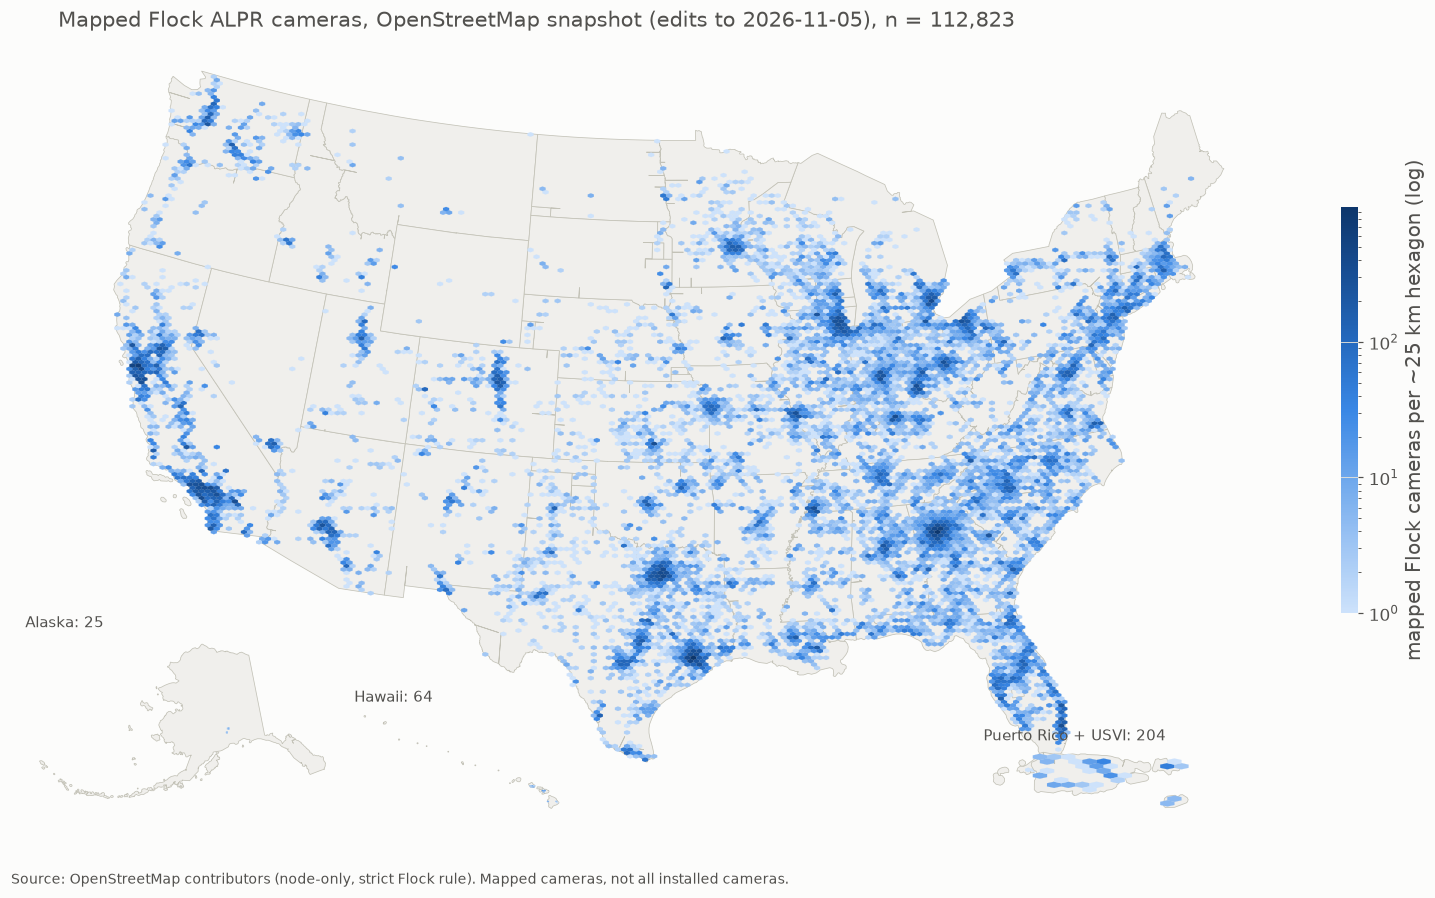

cameras per panel: {'Lower 48 + DC': 112530, 'Alaska': 25, 'Hawaii': 64, 'Puerto Rico + USVI': 204} | not in any panel: 0 | total plotted: 112,823 | densest hexagon: 984


In [20]:
def v1_map(cams: pl.DataFrame):
    cams = cams.with_columns(pl.col("state").map_elements(panel_of, return_dtype=pl.String).alias("panel"))
    fig = plt.figure(figsize=(13, 8.2))
    main = fig.add_axes([0.0, 0.08, 0.92, 0.86])
    axes = {"Lower 48 + DC": main,
            "Alaska": fig.add_axes([0.01, 0.06, 0.22, 0.24]),
            "Hawaii": fig.add_axes([0.24, 0.06, 0.15, 0.15]),
            "Puerto Rico + USVI": fig.add_axes([0.68, 0.06, 0.15, 0.11])}
    sub = cams.filter(pl.col("panel") == "Lower 48 + DC")
    x48, y48 = albers(sub["lon"], sub["lat"], *PANELS["Lower 48 + DC"][1])
    vmax = plt.figure().gca().hexbin(x48, y48, gridsize=int((x48.max() - x48.min()) / 25)).get_array().max(); plt.close()
    norm, stats_ = LogNorm(1, vmax), {"input": cams.height, "panels": {}, "hex_vmax": int(vmax)}
    for name, ax in axes.items():
        sts, prm = PANELS[name]
        sub = cams.filter(pl.col("panel") == name)
        outline = states_geo[states_geo["STATEFP"].map(lambda f: STATES[f][0]).isin(sts) if sts
                             else ~states_geo["STATEFP"].map(lambda f: STATES[f][0]).isin(OUTSIDE_48 | {"GU", "AS", "MP"})]
        for g in outline.geometry:
            gp = project_geom(g, prm)
            for poly in getattr(gp, "geoms", [gp]):
                ax.fill(*poly.exterior.xy, facecolor="#f0efec", edgecolor="#c3c2b7", linewidth=0.5, zorder=0)
        x, y = albers(sub["lon"], sub["lat"], *prm)
        if sub.height:
            span = max(np.ptp(x), np.ptp(y), 50)
            hb = ax.hexbin(x, y, gridsize=max(int(span / 25), 3), cmap=SEQ, norm=norm, mincnt=1, linewidths=0.1, zorder=2)
        ax.set_aspect("equal"); ax.set_axis_off()
        ax.set_title(f"{name}: {sub.height:,}" if ax is not main else "", fontsize=10, color=MUTED, loc="left")
        stats_["panels"][name] = sub.height
    stats_["not_in_any_panel"] = cams.filter(pl.col("panel") == "other").height
    stats_["plotted"] = sum(stats_["panels"].values())
    cb = fig.colorbar(hb, cax=fig.add_axes([0.93, 0.3, 0.012, 0.45]))
    cb.set_label("mapped Flock cameras per ~25 km hexagon (log)", color=MUTED); cb.outline.set_visible(False)
    main.set_title(f"Mapped Flock ALPR cameras, OpenStreetMap snapshot (edits to {cams['timestamp'].max():%Y-%m-%d}), "
                   f"n = {cams.height:,}", loc="left", fontsize=14)
    fig.text(0.0, 0.0, "Source: OpenStreetMap contributors (node-only, strict Flock rule). Mapped cameras, not all installed cameras.",
             color=MUTED, fontsize=9)
    return fig, stats_

fig, s1 = v1_map(flock)
plt.show()
assert s1["plotted"] + s1["not_in_any_panel"] == s1["input"]
print("cameras per panel:", s1["panels"], "| not in any panel:", s1["not_in_any_panel"],
      "| total plotted:", f"{s1['plotted']:,}", "| densest hexagon:", s1["hex_vmax"])

**Interpretation.** Mapped Flock cameras follow population. The densest hexagons are on the large metros (Atlanta,
Houston, Dallas–Fort Worth, Los Angeles, the Bay Area, Chicago, Detroit, Denver, Phoenix, Seattle). The eastern half of
the country, from Texas to Michigan to Georgia, is almost continuously covered; the Mountain West and Great Plains show
scattered clusters along highways and towns. Northern New England is nearly empty. The densest hexagon holds 984
cameras (dev2: 1,106 on its own hex grid; the count per bin depends on where the grid falls).

**Limitation.** This maps *mapped* cameras. A dense area can mean many cameras or many active mappers; an empty area is
not evidence of no cameras. Hexagon colour is a raw count, so it largely tracks where people live.

### V2. Cumulative mapped Flock cameras over time (time series)

Two panels on a shared time axis instead of one chart with two y-scales: new cameras per month (top) and the
running total (bottom). Uses `first_tagged_date` (H3).

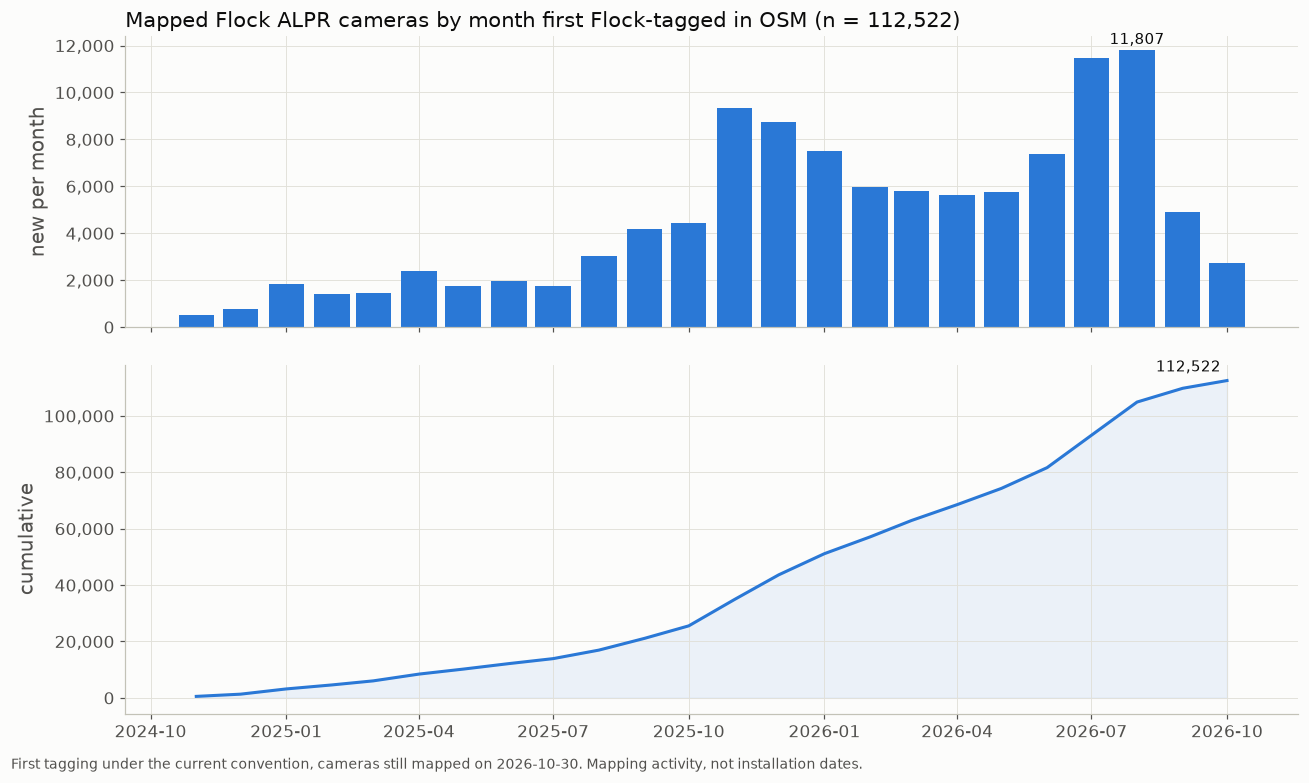

{'dated': 112522, 'undated': 0, 'final_cumulative': 112522, 'nondecreasing': True, 'first_month': '2024-11-01', 'last_day': '2026-10-30', 'peak_month': '2026-08-01', 'peak_new': 11807}


month,new,cumulative
str,u32,u32
"""2024-11""",514,514
"""2024-12""",787,1301
"""2025-01""",1856,3157
"""2025-02""",1421,4578
"""2025-03""",1438,6016
"""2025-04""",2401,8417
"""2025-05""",1767,10184
"""2025-06""",1955,12139
"""2025-07""",1765,13904


In [21]:
def v2_growth(h: pl.DataFrame):
    dated = h.filter("is_flock").drop_nulls("first_tagged_date")
    monthly = (dated.group_by(pl.col("first_tagged_date").dt.truncate("1mo").dt.date().alias("month")).len("new")
                    .sort("month").with_columns(pl.col("new").cum_sum().alias("cumulative")))
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
    a1.bar(monthly["month"], monthly["new"], width=24, color=BLUE, zorder=2)
    a1.set_ylabel("new per month")
    peak = monthly.sort("new", descending=True).row(0, named=True)
    a1.annotate(f"{peak['new']:,}", (peak["month"], peak["new"]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=10, color=INK)
    a2.plot(monthly["month"], monthly["cumulative"], color=BLUE, linewidth=2)
    a2.fill_between(monthly["month"], monthly["cumulative"], color=BLUE, alpha=0.08)
    a2.set_ylabel("cumulative")
    a2.annotate(f"{monthly['cumulative'][-1]:,}", (monthly["month"][-1], monthly["cumulative"][-1]),
                xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=10, color=INK)
    for a in (a1, a2):
        a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a1.set_title(f"Mapped Flock ALPR cameras by month first Flock-tagged in OSM (n = {dated.height:,})", loc="left")
    fig.text(0.01, -0.01, "First tagging under the current convention, cameras still mapped on 2026-10-30. "
             "Mapping activity, not installation dates.", color=MUTED, fontsize=9)
    fig.tight_layout()
    s = {"dated": dated.height, "undated": h.filter("is_flock")["first_tagged_date"].null_count(),
         "final_cumulative": int(monthly["cumulative"][-1]), "nondecreasing": bool((monthly["cumulative"].diff().drop_nulls() >= 0).all()),
         "first_month": str(monthly["month"][0]), "last_day": str(dated["first_tagged_date"].max().date()),
         "peak_month": str(peak["month"]), "peak_new": peak["new"]}
    return fig, s, monthly

fig, s2, monthly = v2_growth(hist)
plt.show()
assert s2["nondecreasing"] and s2["final_cumulative"] == s2["dated"] and s2["undated"] == 0
print(s2)
monthly.with_columns(pl.col("month").dt.strftime("%Y-%m")).select("month", "new", "cumulative")

**Interpretation.** Same history file, so the same curve as dev2. Through mid-2025 the map adds roughly 500–2,400 cameras
a month (12,139 by the end of June 2025). It then accelerates twice: Nov 2025 – Jan 2026 (9,345, 8,749 and 7,509 new)
and Jul–Aug 2026 (11,457 and 11,807, the two biggest months). 42,322 cameras were first tagged in 2025 and 68,899 in
Jan–Oct 2026; September and October 2026 fall back to 4,884 and 2,737.

These bursts look like **mapping campaigns or bulk re-tagging**, not installation waves: 11,800 cameras in one month is
far more than a plausible installation rate, and M3 showed that part of the growth is re-tagging existing objects.

**Limitation.** First appearance of cameras mapped on 2026-10-30 under the current convention. Starts Nov 2024 for
tagging reasons, excludes cameras later deleted, and ends at 112,522, not the snapshot's 112,823 (the 706 newer
cameras have no history date). Mapping activity, not deployment.

### V3. Mapped Flock cameras by state (spatial join + normalisation)

Population is the ACS 2024 5-year total summed over each state's tracts (Puerto Rico included; USVI and the other
island areas are not in the ACS file, so they get no rate).

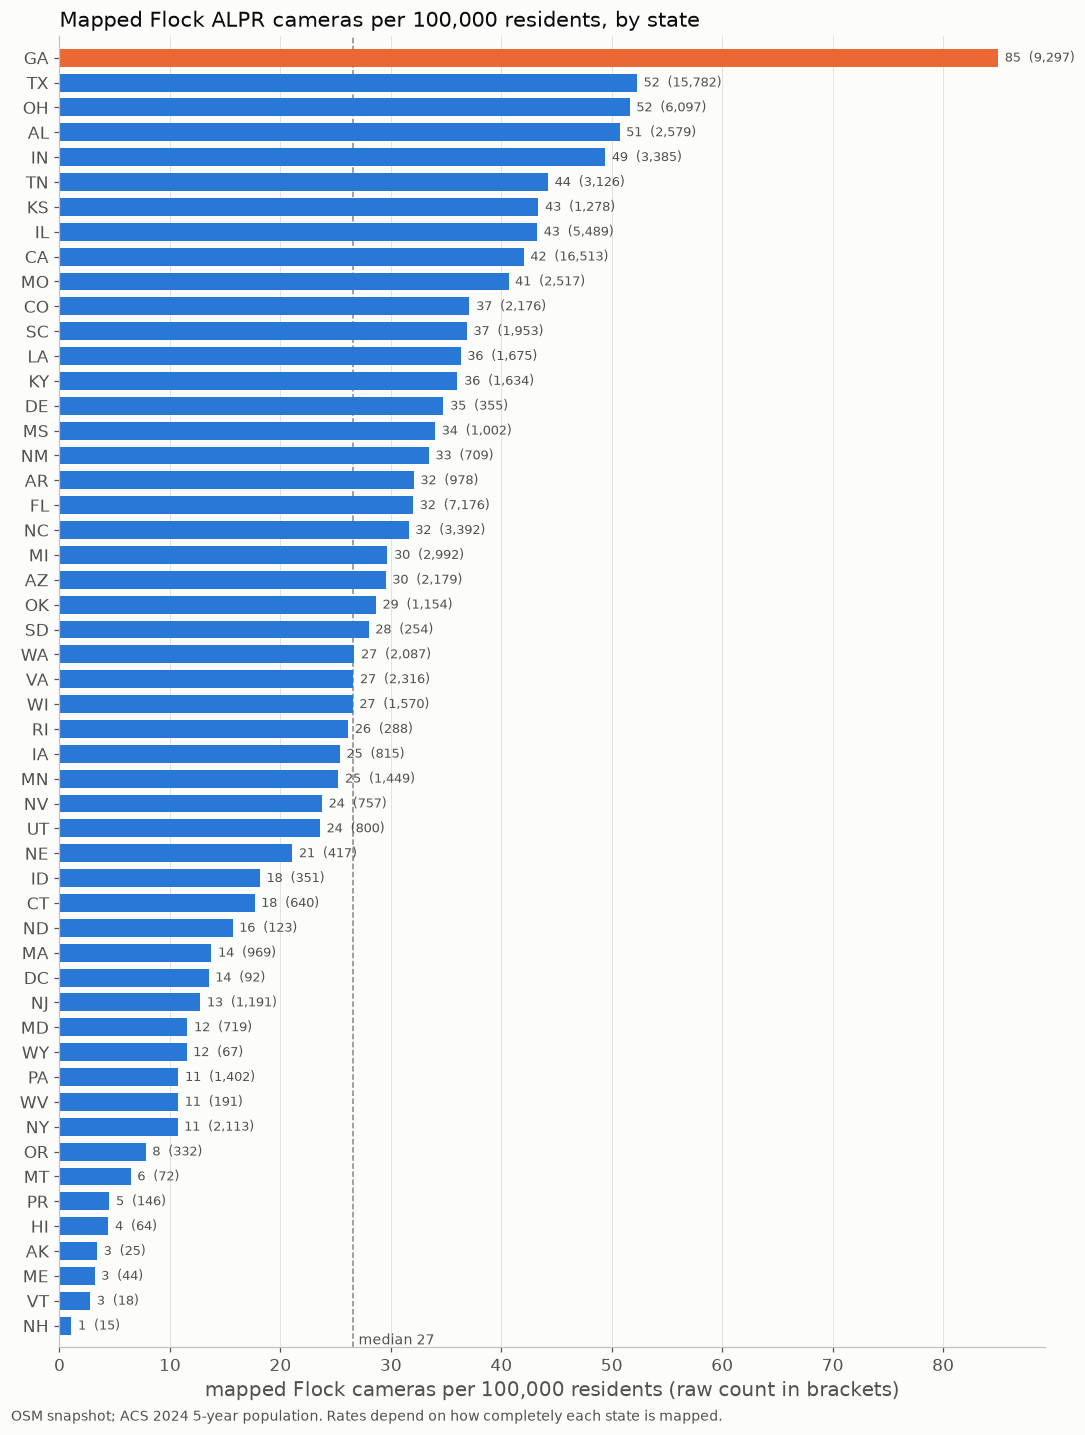

states/territories: 53 | sum of state totals: 112,823 + unassigned 0 = 112,823
Spearman rho, cameras vs population: 0.89


state,state_name,cameras,population,per_100k
str,str,u32,f64,f64
"""CA""","""California""",16513,3.9287377e7,42.0
"""TX""","""Texas""",15782,3.0188424e7,52.3
"""GA""","""Georgia""",9297,1.0940407e7,85.0
"""FL""","""Florida""",7176,2.2416077e7,32.0
"""OH""","""Ohio""",6097,1.1810293e7,51.6
"""IL""","""Illinois""",5489,1.2694798e7,43.2
"""NC""","""North Carolina""",3392,1.0730404e7,31.6
"""IN""","""Indiana""",3385,6.851073e6,49.4
"""TN""","""Tennessee""",3126,7.066383e6,44.2


In [22]:
acs_pop = read_acs(P["acs_pop"], ["B01003_001E", "B01003_001M"]).rename({"B01003_001E": "population", "B01003_001M": "population_moe"})
state_pop = acs_pop.group_by(pl.col("GEOID").str.slice(0, 2).alias("STATEFP")).agg(pl.col("population").sum())

v3 = (by_state.join(state_pop, on="STATEFP", how="left")
              .with_columns((pl.col("cameras") / pl.col("population") * 1e5).alias("per_100k"))
              .join(ff_state.select("state", pl.col("cameras_statewide").alias("ff_all_vendors"), pl.col("flock").alias("ff_flock_listed_cities")),
                    on="state", how="left"))

def v3_by_state(t: pl.DataFrame):
    t = t.drop_nulls("per_100k").sort("per_100k")
    med = t["per_100k"].median()
    fig, ax = plt.subplots(figsize=(10, 13))
    colors = [ORANGE if s == "GA" else BLUE for s in t["state"]]
    ax.barh(t["state"], t["per_100k"], color=colors, height=0.72, zorder=2)
    for i, (r, c) in enumerate(zip(t["per_100k"], t["cameras"])):
        ax.text(r + 0.6, i, f"{r:.0f}  ({c:,})", va="center", fontsize=8.5, color=MUTED)
    ax.axvline(med, color=GREY, linestyle="--", linewidth=1, zorder=1)
    ax.text(med + 0.5, -0.6, f"median {med:.0f}", color=MUTED, fontsize=9, va="center")
    ax.set_xlabel("mapped Flock cameras per 100,000 residents (raw count in brackets)")
    ax.grid(axis="y", visible=False); ax.margins(y=0.01)
    ax.set_title("Mapped Flock ALPR cameras per 100,000 residents, by state", loc="left")
    fig.text(0.01, 0.0, "OSM snapshot; ACS 2024 5-year population. Rates depend on how completely each state is mapped.",
             color=MUTED, fontsize=9)
    fig.tight_layout()
    return fig

fig = v3_by_state(v3)
plt.show()
assert v3["cameras"].sum() == flock.filter(pl.col("state").is_not_null()).height
unassigned = flock.filter(pl.col("state").is_null()).height
print(f"states/territories: {v3.height} | sum of state totals: {v3['cameras'].sum():,} + unassigned {unassigned} = {flock.height:,}")
pop_known = v3.drop_nulls("population")
print("Spearman rho, cameras vs population:", round(stats.spearmanr(pop_known["cameras"], pop_known["population"]).statistic, 2))
v3.select("state", "state_name", "cameras", "population", pl.col("per_100k").round(1)).head(15)

In [23]:
# Cross-check against Finding Flock (replaces dev2's H4 sensitivity layer, whose input is not in the repo).
# Finding Flock's statewide total counts all ALPR vendors; its `flock` column covers listed cities (>= 10 cameras) only.
cmp = v3.drop_nulls("ff_all_vendors").with_columns(
    (pl.col("cameras") / pl.col("ff_all_vendors")).round(2).alias("osm_flock / ff_all_vendors"),
    pl.when(pl.col("ff_flock_listed_cities") > 0).then(pl.col("cameras") / pl.col("ff_flock_listed_cities")).round(2)
      .alias("osm_flock / ff_flock_listed"))
print("states matched to Finding Flock:", cmp.height)
print("Spearman rho, OSM Flock vs Finding Flock all-vendor:", round(stats.spearmanr(cmp["cameras"], cmp["ff_all_vendors"]).statistic, 3))
print(f"OSM Flock total / Finding Flock all-vendor total (matched states): {cmp['cameras'].sum():,} / {cmp['ff_all_vendors'].sum():,} "
      f"= {cmp['cameras'].sum() / cmp['ff_all_vendors'].sum():.2f}")
cmp.sort("osm_flock / ff_all_vendors").select("state", "cameras", "ff_all_vendors", "ff_flock_listed_cities",
                                             "osm_flock / ff_all_vendors", "osm_flock / ff_flock_listed").head(10)

states matched to Finding Flock: 52
Spearman rho, OSM Flock vs Finding Flock all-vendor: 0.976
OSM Flock total / Finding Flock all-vendor total (matched states): 112,765 / 145,223 = 0.78


state,cameras,ff_all_vendors,ff_flock_listed_cities,osm_flock / ff_all_vendors,osm_flock / ff_flock_listed
str,u32,i64,i64,f64,f64
"""NH""",15,80,0,0.19,null
"""PA""",1402,3974,558,0.35,2.51
"""ME""",44,104,16,0.42,2.75
"""NY""",2113,4793,936,0.44,2.26
"""NJ""",1191,2449,375,0.49,3.18
"""PR""",146,278,55,0.53,2.65
"""VT""",18,31,0,0.58,null
"""KS""",1278,2106,748,0.61,1.71
"""CT""",640,1045,188,0.61,3.4


**Interpretation.** Raw counts are concentrated: California, Texas, Georgia, Florida and Ohio hold 48.6% of mapped Flock
cameras, and state totals track population closely (Spearman ρ = 0.89). Normalising changes the picture. The median
state has about 27 cameras per 100,000 residents. **Georgia is the clear outlier at 85 per 100,000**, Flock's home
state, ahead of Texas (52), Ohio (52), Alabama (51) and Indiana (49); California drops to the middle (42). New
England is lowest: New Hampshire (1.1), Vermont (2.8) and Maine (3.2), along with Alaska (3.4), Hawaii (4.4) and Puerto
Rico (4.5). New York and Pennsylvania are both about 11 despite large populations. USVI has no ACS population, so no rate.

**Cross-check (Finding Flock).** dev2's sensitivity layer for the strict tag rule (H4) needs a file that is not in the
repo, so V3 is checked against the Finding Flock state table instead. State rankings agree almost perfectly with Finding
Flock's all-vendor totals (ρ = 0.98), and the OSM Flock count is 78% of their all-vendor total. The lowest shares are in
the Northeast (NH 0.19, PA 0.35, ME 0.42, NY 0.44, NJ 0.49), where other ALPR vendors are more common, or Flock cameras
are less completely mapped, or both. These sources cannot separate the two.

**Limitation.** Per-capita rates depend on how completely each state is mapped and on the tag rule. They are not crime or
policy measures.

### M4 summary

- **Passed:** V1 panels sum to 112,823 with none dropped; V2 is nondecreasing and ends at 112,522 dated cameras (0
  undated); V3 state totals sum to 112,823 with 0 unassigned.
- **Not reproduced:** the H4 sensitivity layer (input not in repo), replaced by the Finding Flock cross-check.

## M5. Community-level analytical table (Census tracts)

Goal: **one row per Census tract**, starting from the complete tract boundary file so zero-camera tracts are kept,
with camera counts, ACS population, income, poverty and race/ethnicity, and documented denominators.

| Decision | Choice | Why |
|---|---|---|
| Geography | Census tract, 2020 geography (**TIGER 2024** per-state files, 50 states + DC) | ACS 2024 uses the same tracts; TIGER is what the repo has (dev2 used the 1:500k cartographic file) |
| Demographics | ACS 2024 5-year: B01003 population, B19013 median household income, S1701 % below poverty, B03002 race/ethnicity | All four are in the repo; 5-year is the only ACS product for tracts |
| Camera density | cameras per 10,000 residents (null at 0 residents), plus cameras per km² of land (`ALAND`) | Same as dev2 |
| Crime | **none** — no crime data in the repo | V5 uses poverty and race instead |
| Low population | tracts with < 500 residents flagged `low_population`, not dropped | Per-resident rates explode there |

In [24]:
tract_files = sorted(P["tracts_2024"].glob("tl_2024_*_tract.zip"))
tracts_geo = pd.concat([gpd.read_file(f"zip://{f.as_posix()}", columns=["GEOID", "STATEFP", "COUNTYFP", "ALAND"]) for f in tract_files],
                       ignore_index=True)
tracts_geo = gpd.GeoDataFrame(tracts_geo, geometry="geometry", crs=counties.crs)
print("tract files:", len(tract_files), "| tracts:", f"{len(tracts_geo):,}")

income = read_acs(P["acs_income"], ["B19013_001E", "B19013_001M"]).rename({"B19013_001E": "median_income", "B19013_001M": "median_income_moe"})
income_raw = read_acs(P["acs_income"], ["B19013_001E"], parse=False)
poverty = read_acs(P["acs_poverty"], ["S1701_C01_001E", "S1701_C03_001E"]).rename(
    {"S1701_C01_001E": "poverty_universe", "S1701_C03_001E": "pct_poverty"})
race = (read_acs(P["acs_race"], ["B03002_001E", "B03002_003E", "B03002_004E", "B03002_012E"])
        .with_columns((pl.col("B03002_003E") / pl.col("B03002_001E") * 100).alias("pct_nh_white"),
                      (pl.col("B03002_004E") / pl.col("B03002_001E") * 100).alias("pct_nh_black"),
                      (pl.col("B03002_012E") / pl.col("B03002_001E") * 100).alias("pct_hispanic"))
        .select("GEOID", "pct_nh_white", "pct_nh_black", "pct_hispanic"))
acs = acs_pop.join(income, on="GEOID").join(poverty, on="GEOID").join(race, on="GEOID")

cam_tract = assign_polygons(flock, tracts_geo, ["GEOID"])
cam_counts = cam_tract.drop_nulls("GEOID").group_by("GEOID").len("cameras")

city = gpd.read_file(P["chicago_city"]).geometry.union_all()
rep = tracts_geo[tracts_geo["STATEFP"] == "17"].copy()
chicago_ids = set(rep.loc[rep.geometry.representative_point().within(city), "GEOID"])

tract = (
    pl.from_pandas(pd.DataFrame(tracts_geo.drop(columns="geometry")))
    .join(STATE_DF, on="STATEFP", how="left")
    .join(acs, on="GEOID", how="left")
    .join(cam_counts, on="GEOID", how="left")
    .with_columns(
        pl.col("cameras").fill_null(0),
        (pl.col("ALAND") / 1e6).alias("land_km2"),
        pl.col("population").is_not_null().alias("acs_available"),
        pl.col("GEOID").is_in(list(chicago_ids)).alias("in_chicago"),
    )
    .with_columns(
        pl.when(pl.col("population") > 0).then(pl.col("cameras") / pl.col("population") * 1e4).alias("cameras_per_10k"),
        pl.when(pl.col("land_km2") > 0).then(pl.col("cameras") / pl.col("land_km2")).alias("cameras_per_km2"),
        (pl.col("population") < 500).alias("low_population"),
    )
)
print("shape:", tract.shape)
tract.glimpse()

tract files: 51 | tracts: 84,415


shape: (84415, 22)
Rows: 84415
Columns: 22
$ STATEFP            <str> '01', '01', '01', '01', '01', '01', '01', '01', '01', '01'
$ COUNTYFP           <str> '063', '063', '069', '069', '069', '069', '069', '069', '069', '069'
$ GEOID              <str> '01063060102', '01063060101', '01069040802', '01069040204', '01069041902', '01069040205', '01069040203', '01069040801', '01069041901', '01069040206'
$ ALAND              <i64> 423259520, 79177219, 31146753, 11747450, 141641460, 8597200, 14602533, 20146185, 37528653, 9908157
$ state              <str> 'AL', 'AL', 'AL', 'AL', 'AL', 'AL', 'AL', 'AL', 'AL', 'AL'
$ state_name         <str> 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama', 'Alabama'
$ population         <f64> 2263.0, 1598.0, 4184.0, 6346.0, 4863.0, 5802.0, 2902.0, 5440.0, 3002.0, 4040.0
$ population_moe     <f64> 305.0, 286.0, 361.0, 650.0, 305.0, 522.0, 267.0, 623.0, 302.0, 293.0
$ median_income      <f64> 36437.0, 23475.0, 5468

In [25]:
# --- acceptance checks ----------------------------------------------------------------------------------------
acs_ids, bnd_ids = set(acs["GEOID"]), set(tract["GEOID"])
cam_in = flock.height
print("one row per tract (duplicate GEOID)     :", tract["GEOID"].is_duplicated().sum())
print("tracts kept / with ACS                  :", f"{tract.height:,} / {tract['acs_available'].sum():,}")
print("tracts with >= 1 camera                 :", f"{(tract['cameras'] > 0).sum():,}", f"({(tract['cameras'] > 0).mean():.1%}); the rest are kept with 0")
print("cameras: within / nearest / unmatched   :", cam_tract["match"].value_counts(sort=True).rows())
unm = cam_tract.filter(pl.col("GEOID").is_null()).join(flock.select("osm_id", "state"), on="osm_id")
print("  unmatched by state                    :", unm["state"].value_counts(sort=True).rows())
print("sum of tract counts                     :", f"{int(tract['cameras'].sum()):,}", "(Flock snapshot:", f"{cam_in:,})")
print("tracts without ACS                      :", tract.filter(~pl.col("acs_available")).group_by("state").len().rows())
acs_only = acs.filter(~pl.col("GEOID").is_in(list(bnd_ids)))
print("ACS tracts with no boundary             :", acs_only.height, "by state:", acs_only["GEOID"].str.slice(0, 2).value_counts().rows(),
      "| population:", f"{int(acs_only['population'].sum()):,}")
print("zero-population tracts / < 500 residents:", tract.filter(pl.col("population") == 0).height, "/",
      tract.filter(pl.col("low_population")).height, f"(holding {int(tract.filter(pl.col('low_population'))['cameras'].sum())} cameras)")
print("ACS tracts without an income estimate   :", tract.filter(pl.col("acs_available") & pl.col("median_income").is_null()).height,
      "| top-coded at $250,001:", income_raw.filter(pl.col("B19013_001E") == "250,000+").height)
print("ACS tracts without a poverty rate       :", tract.filter(pl.col("acs_available") & pl.col("pct_poverty").is_null()).height)

one row per tract (duplicate GEOID)     : 0
tracts kept / with ACS                  : 84,415 / 84,401
tracts with >= 1 camera                 : 35,327 (41.8%); the rest are kept with 0
cameras: within / nearest / unmatched   : [('within', 112613), (None, 204), ('nearest', 6)]
  unmatched by state                    : [('PR', 146), ('VI', 58)]
sum of tract counts                     : 112,619 (Flock snapshot: 112,823)
tracts without ACS                      : [('NY', 14)]
ACS tracts with no boundary             : 981 by state: [('72', 981)] | population: 3,234,309
zero-population tracts / < 500 residents: 793 / 1057 (holding 684 cameras)
ACS tracts without an income estimate   : 1488 | top-coded at $250,001: 553
ACS tracts without a poverty rate       : 983


In [26]:
# --- how cameras are distributed over tracts (ACS tracts only) -----------------------------------------------
acs_t = tract.filter("acs_available")
print(acs_t.select(pl.col("cameras").mean().round(2).alias("mean"), pl.col("cameras").median().alias("median"),
                   pl.col("cameras").quantile(0.9).alias("p90"), pl.col("cameras").max().alias("max"),
                   (pl.col("cameras") == 0).mean().round(3).alias("share_zero")))
print("median relative MOE: income", round(acs_t.select((pl.col("median_income_moe") / pl.col("median_income")).median()).item(), 3),
      "| population", round(acs_t.select((pl.col("population_moe") / pl.col("population")).median()).item(), 3))
acs_t.sort("cameras", descending=True).select("GEOID", "state", "population", pl.col("land_km2").round(1), "cameras",
                                              pl.col("cameras_per_10k").round(1), "low_population").head(6)

shape: (1, 5)
┌──────┬────────┬─────┬─────┬────────────┐
│ mean ┆ median ┆ p90 ┆ max ┆ share_zero │
│ ---  ┆ ---    ┆ --- ┆ --- ┆ ---        │
│ f64  ┆ f64    ┆ f64 ┆ u32 ┆ f64        │
╞══════╪════════╪═════╪═════╪════════════╡
│ 1.33 ┆ 0.0    ┆ 4.0 ┆ 80  ┆ 0.581      │
└──────┴────────┴─────┴─────┴────────────┘
median relative MOE: income 0.206 | population 0.138


GEOID,state,population,land_km2,cameras,cameras_per_10k,low_population
str,str,f64,f64,u32,f64,bool
"""53053070403""","""WA""",4684.0,13.5,80,170.8,false
"""04013071600""","""AZ""",3837.0,2.6,76,198.1,false
"""39041012400""","""OH""",10876.0,9.7,63,57.9,false
"""53053070404""","""WA""",5511.0,5.1,60,108.9,false
"""17089854600""","""IL""",4190.0,1.9,57,136.0,false
"""48439980000""","""TX""",0.0,46.1,57,null,true


In [27]:
# --- Chicago subset (for V6) -----------------------------------------------------------------------------------
chi = tract.filter("in_chicago")
print("Chicago tracts:", chi.height, "| residents:", f"{int(chi['population'].sum()):,}", "| mapped Flock cameras:", int(chi["cameras"].sum()),
      "in", chi.filter(pl.col("cameras") > 0).height, "tracts")

Chicago tracts: 783 | residents: 2,675,036 | mapped Flock cameras: 100 in 48 tracts


**What stands out (tract table)**

- **84,415 tracts, one row each, none dropped** (dev2 had 85,184 because its cartographic file included the island
  areas). 84,401 have ACS data; the 14 without are the same **Suffolk County, NY tracts** dev2 found, whose 2024
  boundary codes are not in the ACS 2024 tables.
- **Puerto Rico has ACS but no boundaries in the repo**: 981 ACS tracts (3.2 million residents) have no polygon, so the
  146 PR and 58 USVI cameras are not in any tract. Every other camera lands in one: 112,613 inside, 6 assigned to the
  nearest tract, and tract counts sum to 112,619 = 112,823 − 204.
- **Most tracts have no mapped camera**: 58.1% of ACS tracts have zero; the median is 0, the mean 1.33, the 90th
  percentile 4, the maximum 80 (a Pierce County, WA tract). Keeping zero-camera tracts is what stops "most
  neighbourhoods have none" turning into "every neighbourhood has some".
- **Denominators bite.** The DFW airport tract (Tarrant County, TX) has 0 residents and 57 cameras: its per-resident rate
  is null by design. 1,057 tracts have under 500 residents (684 cameras); 793 have none (TIGER includes all-water
  tracts, which dev2's cartographic file left out).
- **ACS uncertainty is real:** median relative margin of error is about ±21% for income and ±14% for population.
- **Chicago is thin:** 783 tracts and 2.7 million residents, but only **100 mapped Flock cameras in 48 tracts**.

### M5 summary

- **Passed:** one row per tract, zero-camera tracts kept, camera counts reconcile exactly, denominators documented.
- **Limitations:** no PR tracts; no crime data (V5 replaced); ACS margins large for small tracts; Suffolk vintage gap.

## M6. Q2 — Is mapped camera density associated with community characteristics? (V4–V6)

Every result below is an **observational association** between where cameras are *mapped* and tract characteristics;
none says why cameras were placed where they are. All three use the M5 tract table.

### V4. Camera density by neighbourhood income

Tracts are split into **national quintiles of median household income** (equal numbers of tracts). The left panel
pools each group (all cameras ÷ all residents × 10,000); error bars are 95% bootstrap intervals over tracts. The right
panel is the share of tracts with at least one camera. Zero-camera tracts are included in both.

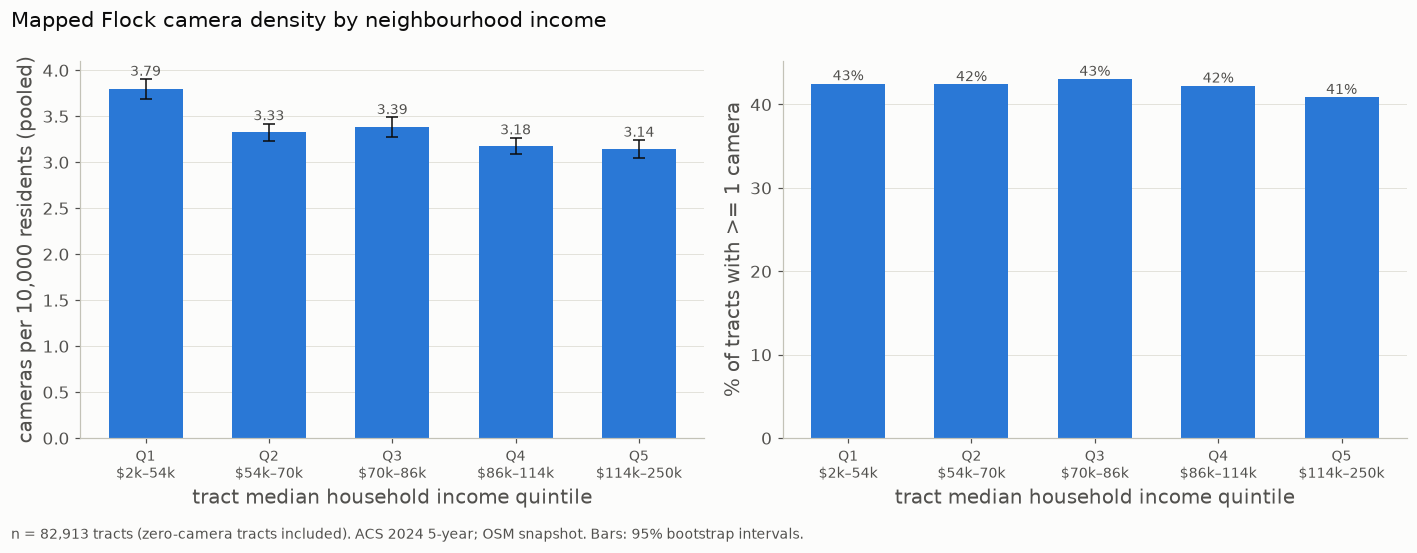

tracts in quintiles: 82,913 (zero-camera: 47,912) | excluded, no income or 0 residents: 1,488 tracts / 1,235 cameras | no ACS: 14 tracts / 2 cameras
Spearman rho, income vs cameras per 10k (tract level): -0.028


quintile,tracts,income_min,income_max,cameras,pooled_per_10k,ci_lo,ci_hi,share_tracts_with_camera,low_pop_tracts
i64,i64,f64,f64,i64,f64,f64,f64,f64,i64
1,16583,2499.0,53804.0,20756,3.79,3.68,3.9,0.425,27
2,16583,53806.0,69591.0,20768,3.33,3.23,3.42,0.424,11
3,16582,69592.0,86406.0,22782,3.39,3.28,3.49,0.43,9
4,16583,86406.0,113786.0,23063,3.18,3.09,3.27,0.422,16
5,16582,113787.0,250001.0,24013,3.14,3.04,3.24,0.409,22


In [28]:
elig = tract.filter(pl.col("acs_available") & pl.col("median_income").is_not_null() & (pl.col("population") > 0))

def quintile_table(df: pl.DataFrame, col: str, label: str) -> pl.DataFrame:
    df = df.drop_nulls(col).with_columns((pl.col(col).rank("ordinal") - 1).mul(5).floordiv(pl.len()).add(1).alias("quintile"))
    rows = []
    for q in range(1, 6):
        g = df.filter(pl.col("quintile") == q)
        est, lo, hi = pooled_rate(g["cameras"].to_numpy(), g["population"].to_numpy())
        rows.append({"quintile": q, "tracts": g.height, f"{label}_min": g[col].min(), f"{label}_max": g[col].max(),
                     "cameras": int(g["cameras"].sum()), "pooled_per_10k": est, "ci_lo": lo, "ci_hi": hi,
                     "share_tracts_with_camera": (g["cameras"] > 0).mean(), "low_pop_tracts": int(g["low_population"].sum())})
    return pl.DataFrame(rows)

def quintile_figure(tab: pl.DataFrame, label_fmt, xlabel: str, title: str):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
    x = np.arange(1, 6)
    names = [label_fmt(r) for r in tab.iter_rows(named=True)]
    a1.bar(x, tab["pooled_per_10k"], color=BLUE, width=0.6, zorder=2)
    a1.errorbar(x, tab["pooled_per_10k"], yerr=[tab["pooled_per_10k"] - tab["ci_lo"], tab["ci_hi"] - tab["pooled_per_10k"]],
                fmt="none", ecolor=INK, capsize=4, linewidth=1, zorder=3)
    a1.set_ylabel("cameras per 10,000 residents (pooled)")
    a2.bar(x, tab["share_tracts_with_camera"] * 100, color=BLUE, width=0.6, zorder=2)
    a2.set_ylabel("% of tracts with >= 1 camera")
    for a in (a1, a2):
        a.set_xticks(x, names, fontsize=9); a.set_xlabel(xlabel); a.grid(axis="x", visible=False)
    for i, r in enumerate(tab.iter_rows(named=True)):
        a1.text(x[i], r["ci_hi"], f"{r['pooled_per_10k']:.2f}", ha="center", va="bottom", fontsize=9, color=MUTED)
        a2.text(x[i], r["share_tracts_with_camera"] * 100, f"{r['share_tracts_with_camera']:.0%}", ha="center", va="bottom", fontsize=9, color=MUTED)
    fig.suptitle(title, x=0.01, ha="left", fontsize=14)
    fig.text(0.01, -0.02, f"n = {tab['tracts'].sum():,} tracts (zero-camera tracts included). ACS 2024 5-year; OSM snapshot. "
             "Bars: 95% bootstrap intervals.", color=MUTED, fontsize=9)
    fig.tight_layout()
    return fig

v4tab = quintile_table(elig, "median_income", "income")
fig = quintile_figure(v4tab, lambda r: f"Q{r['quintile']}\n${r['income_min'] / 1e3:.0f}k–{r['income_max'] / 1e3:.0f}k",
                      "tract median household income quintile", "Mapped Flock camera density by neighbourhood income")
plt.show()
excl = tract.filter(pl.col("acs_available")).filter(pl.col("median_income").is_null() | (pl.col("population") <= 0))
no_acs = tract.filter(~pl.col("acs_available"))
assert v4tab["cameras"].sum() + excl["cameras"].sum() + no_acs["cameras"].sum() == tract["cameras"].sum()
print(f"tracts in quintiles: {v4tab['tracts'].sum():,} (zero-camera: {(elig['cameras'] == 0).sum():,}) | "
      f"excluded, no income or 0 residents: {excl.height:,} tracts / {int(excl['cameras'].sum()):,} cameras | "
      f"no ACS: {no_acs.height} tracts / {int(no_acs['cameras'].sum())} cameras")
print("Spearman rho, income vs cameras per 10k (tract level):",
      round(stats.spearmanr(elig["median_income"], elig["cameras_per_10k"]).statistic, 3))
v4tab.with_columns(pl.col(c).round(2) for c in ["pooled_per_10k", "ci_lo", "ci_hi"]).with_columns(pl.col("share_tracts_with_camera").round(3))

In [29]:
# Robustness: national quintiles mix regions with different costs of living. Rank tracts within their own state instead.
within = elig.with_columns(pl.col("median_income").rank("ordinal").over("state").alias("_r"), pl.len().over("state").alias("_n")) \
             .with_columns(((pl.col("_r") - 1) * 5 // pl.col("_n") + 1).alias("within_state_quintile"))
within.group_by("within_state_quintile").agg(
    pl.len().alias("tracts"), (pl.col("cameras").sum() / pl.col("population").sum() * 10_000).round(2).alias("pooled_per_10k"),
    (pl.col("cameras") > 0).mean().round(3).alias("share_with_camera")).sort("within_state_quintile")

within_state_quintile,tracts,pooled_per_10k,share_with_camera
u32,u32,f64,f64
1,16604,3.49,0.399
2,16581,3.24,0.412
3,16584,3.34,0.425
4,16581,3.28,0.434
5,16563,3.37,0.44


**Interpretation.** Nationally, mapped Flock camera density is **nearly flat across income, with the lowest-income
quintile slightly higher**. The pooled rate is 3.79 per 10,000 residents in the lowest quintile (95% CI 3.68–3.90) and
3.14–3.39 in the other four, and the share of tracts with any camera is 41–43% in every quintile. At the tract level the
rank correlation between income and density is essentially zero (ρ = −0.03). Ranking tracts within their own state
gives an even flatter picture (3.24–3.49 per 10,000), so the small national bump in Q1 is partly a between-state effect.

**Limitation.** Group averages hide variation, and income quintiles also differ in urbanicity, region and road network,
none of which is controlled. 1,488 tracts with no income estimate or no residents are excluded (1,235 cameras), plus
the 14 Suffolk tracts (2 cameras) and the 204 PR/USVI cameras that have no tract. A flat national pattern can hide
opposite local patterns (V6 shows one).

### V5. Camera density by poverty rate and by race/ethnicity *(replaces dev2's crime figure)*

dev2's V5 compared density with 2023 Chicago crime; that file is not in the repo. The repo does have ACS poverty
(S1701) and race/ethnicity (B03002), so V5 asks the same Q2 question with two other community characteristics, using
the same pooled-quintile design as V4: tracts by **% of residents below the poverty line** and by **% non-Hispanic
white** (lower = more residents of colour).

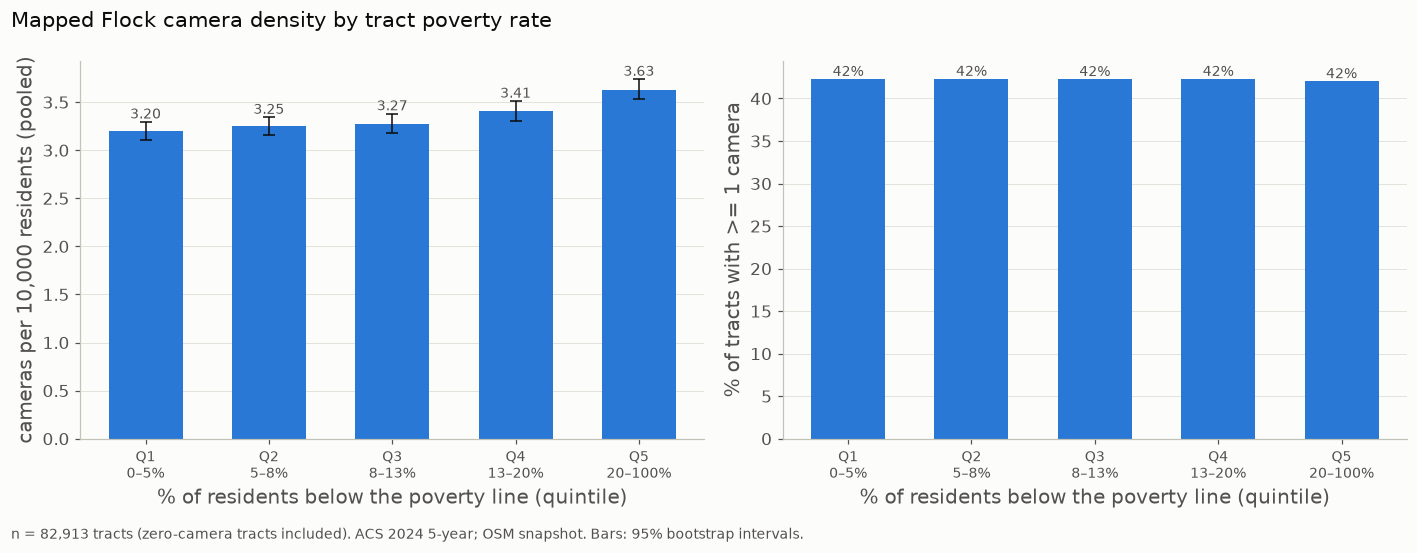

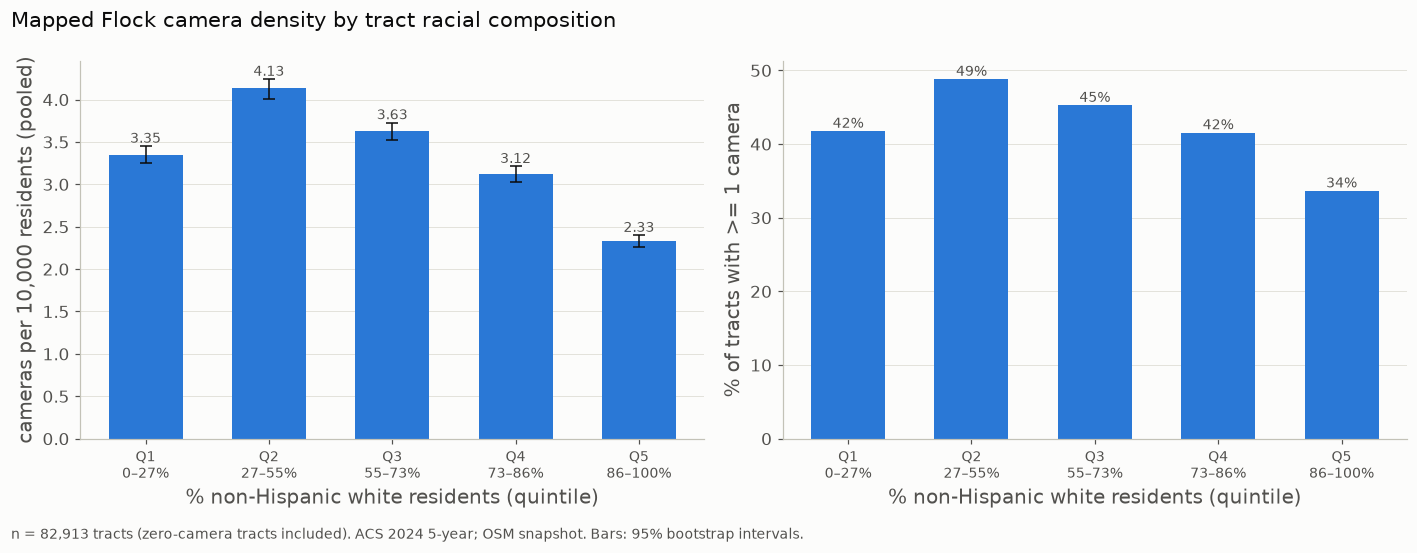

Spearman rho, poverty    vs cameras per 10k: +0.016  (n = 82,913)
Spearman rho, % NH white vs cameras per 10k: -0.071  (n = 82,913)
Spearman rho, % NH Black vs cameras per 10k: +0.109  (n = 82,913)
Spearman rho, % Hispanic vs cameras per 10k: +0.056  (n = 82,913)


by,quintile,tracts,pct_min,pct_max,cameras,pooled_per_10k,ci_lo,ci_hi,share_tracts_with_camera
str,i64,i64,f64,f64,i64,f64,f64,f64,f64
"""poverty""",1,16583,0.0,5.0,23681,3.2,3.1,3.3,0.423
"""poverty""",2,16583,5.0,8.5,22872,3.25,3.16,3.34,0.423
"""poverty""",3,16582,8.5,13.0,21940,3.27,3.18,3.38,0.423
"""poverty""",4,16583,13.0,20.3,21830,3.41,3.3,3.51,0.423
"""poverty""",5,16582,20.3,100.0,21059,3.63,3.53,3.74,0.42
"""% NH white""",1,16583,0.0,27.4,22493,3.35,3.25,3.45,0.418
"""% NH white""",2,16583,27.4,55.3,29059,4.13,4.01,4.24,0.488
"""% NH white""",3,16582,55.3,73.4,24883,3.63,3.53,3.73,0.453
"""% NH white""",4,16583,73.4,86.4,20942,3.12,3.02,3.21,0.416


In [30]:
v5_pov = quintile_table(elig, "pct_poverty", "pct")
fig = quintile_figure(v5_pov, lambda r: f"Q{r['quintile']}\n{r['pct_min']:.0f}–{r['pct_max']:.0f}%",
                      "% of residents below the poverty line (quintile)", "Mapped Flock camera density by tract poverty rate")
plt.show()
v5_race = quintile_table(elig, "pct_nh_white", "pct")
fig = quintile_figure(v5_race, lambda r: f"Q{r['quintile']}\n{r['pct_min']:.0f}–{r['pct_max']:.0f}%",
                      "% non-Hispanic white residents (quintile)", "Mapped Flock camera density by tract racial composition")
plt.show()
for name, col in [("poverty", "pct_poverty"), ("% NH white", "pct_nh_white"), ("% NH Black", "pct_nh_black"), ("% Hispanic", "pct_hispanic")]:
    d = elig.drop_nulls(col)
    print(f"Spearman rho, {name:10s} vs cameras per 10k: {stats.spearmanr(d[col], d['cameras_per_10k']).statistic:+.3f}  (n = {d.height:,})")
pl.concat([v5_pov.select(pl.lit("poverty").alias("by"), "quintile", "tracts", pl.col("pct_min").round(1), pl.col("pct_max").round(1), "cameras",
                         pl.col("pooled_per_10k").round(2), pl.col("ci_lo").round(2), pl.col("ci_hi").round(2), pl.col("share_tracts_with_camera").round(3)),
           v5_race.select(pl.lit("% NH white").alias("by"), "quintile", "tracts", pl.col("pct_min").round(1), pl.col("pct_max").round(1), "cameras",
                          pl.col("pooled_per_10k").round(2), pl.col("ci_lo").round(2), pl.col("ci_hi").round(2), pl.col("share_tracts_with_camera").round(3))])

In [31]:
# Is the race pattern just urban vs rural? Repeat within population-density terciles (residents per km2).
dens = elig.drop_nulls("pct_nh_white").filter(pl.col("land_km2") > 0).with_columns(
    (pl.col("population") / pl.col("land_km2")).alias("pop_density"))
dens = dens.with_columns(((pl.col("pop_density").rank("ordinal") - 1) * 3 // pl.len() + 1).alias("density_tercile"),
                         ((pl.col("pct_nh_white").rank("ordinal") - 1) * 5 // pl.len() + 1).alias("white_quintile"))
(dens.group_by("density_tercile", "white_quintile")
     .agg((pl.col("cameras").sum() / pl.col("population").sum() * 1e4).round(2).alias("per_10k"))
     .pivot(on="white_quintile", index="density_tercile", values="per_10k", sort_columns=True).sort("density_tercile"))

density_tercile,1,2,3,4,5
u32,f64,f64,f64,f64,f64
1,4.91,5.61,4.47,3.39,2.26
2,5.54,5.32,4.14,3.43,2.68
3,2.34,2.67,2.17,1.71,1.59


In [32]:
# Is it regional? Rank tracts by % non-Hispanic white within their own state (as in the V4 robustness check).
w = elig.drop_nulls("pct_nh_white").with_columns(
    pl.col("pct_nh_white").rank("ordinal").over("state").alias("_r"), pl.len().over("state").alias("_n")
).with_columns(((pl.col("_r") - 1) * 5 // pl.col("_n") + 1).alias("within_state_white_quintile"))
w.group_by("within_state_white_quintile").agg(
    pl.len().alias("tracts"), (pl.col("cameras").sum() / pl.col("population").sum() * 10_000).round(2).alias("pooled_per_10k"),
    (pl.col("cameras") > 0).mean().round(3).alias("share_with_camera")).sort("within_state_white_quintile")

within_state_white_quintile,tracts,pooled_per_10k,share_with_camera
u32,u32,f64,f64
1,16604,3.19,0.407
2,16581,3.72,0.452
3,16584,3.63,0.452
4,16581,3.18,0.422
5,16563,2.9,0.378


**Interpretation (poverty).** Density **rises slightly with tract poverty**: 3.20 per 10,000 in the lowest-poverty
quintile to 3.63 in the highest (intervals do not overlap at the ends), while the share of tracts with a camera is flat
at 42% throughout. The tract-level correlation is close to zero (ρ = +0.02). Same picture as V4 from the other side.

**Interpretation (race/ethnicity).** This is the one clear gradient in Q2. Tracts that are **mostly non-Hispanic white
have the lowest density**: 2.33 per 10,000 in the whitest quintile (86–100% white) against 4.13 in the 27–55% quintile,
and 34% vs 49% of tracts with a camera. The pattern is an inverted U, not a straight line: the least-white quintile
(0–27%) is in between (3.35). At the tract level the correlation is weak (ρ = −0.07 for % white, +0.11 for % Black).

Two checks on what drives it:
- **Not just urban vs rural.** Within each population-density tercile the whitest quintile is still the lowest (e.g.
  2.26 vs 5.61 per 10,000 in the least dense third).
- **Partly regional.** Ranking tracts within their own state shrinks the gap from 4.13 vs 2.33 to 3.72 vs 2.90. The
  states with the highest rates (Georgia, Alabama, Texas) have large Black and Hispanic populations; the lowest (New
  Hampshire, Vermont, Maine) are among the whitest. About half the national gap is between states; the rest remains
  within them.

**Limitation.** These are associations between where cameras are *mapped* and tract composition. They cannot say why
cameras are where they are, and mapping completeness may itself vary with neighbourhood. This replaces dev2's crime
figure; it does not answer the crime question.

### V6. Neighbourhood income and mapped cameras, Chicago area

The nine Illinois counties of the Chicago area: tracts shaded by ACS median household income in five fixed dollar
classes, every mapped Flock camera as a point, and the City of Chicago outlined.

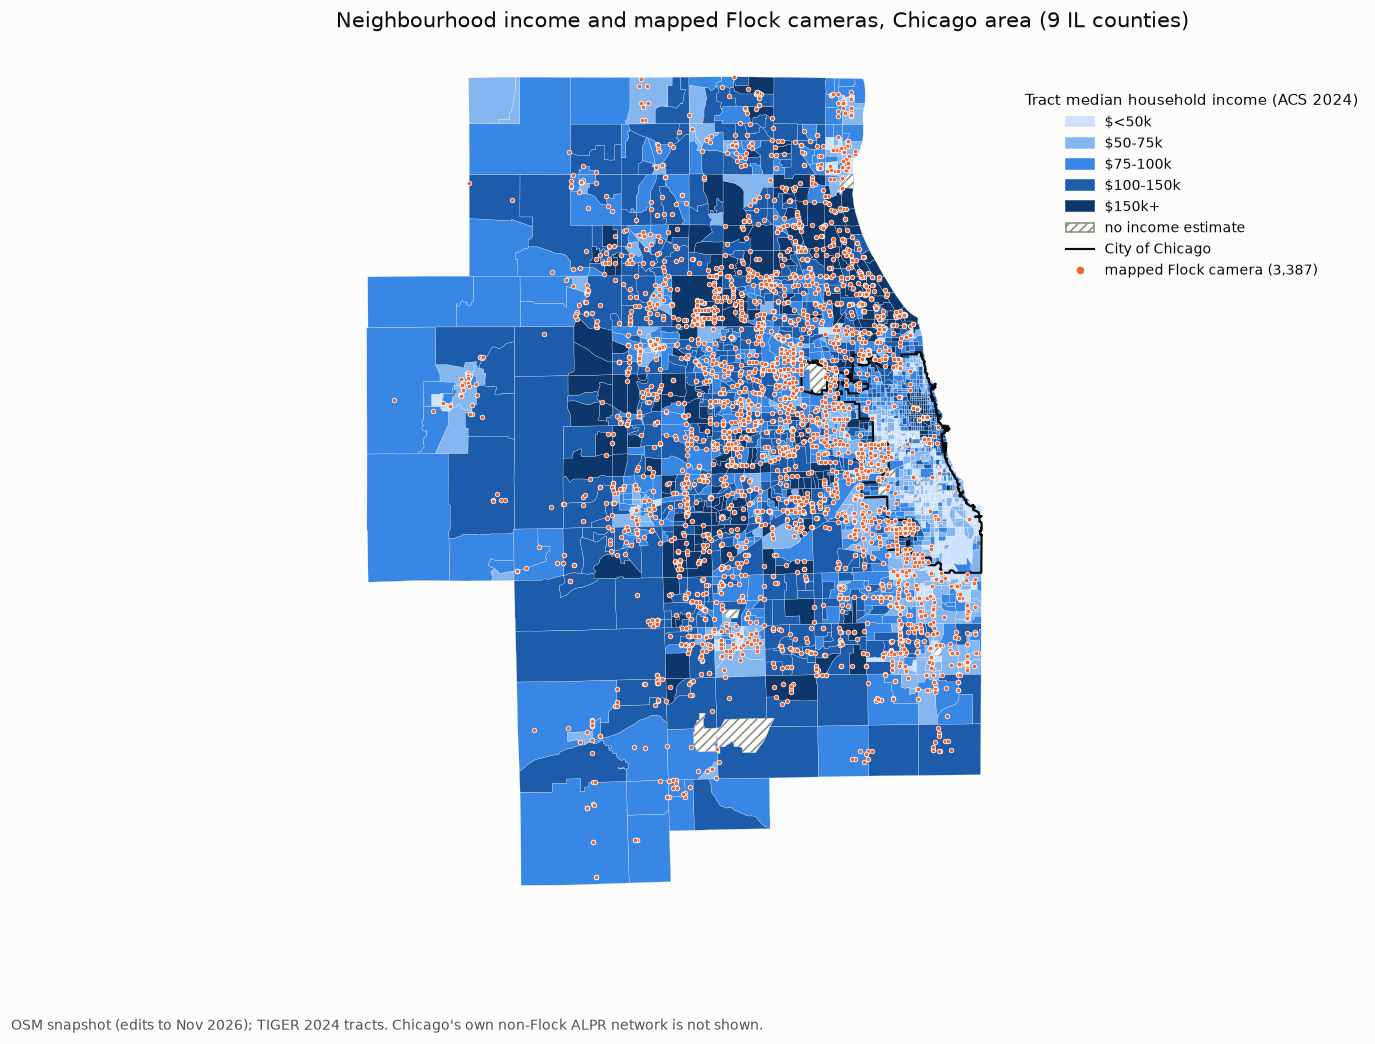

{'tracts': 2105, 'water_tracts_not_drawn': 2, 'land_tracts_no_income': 26, 'cameras_plotted': 3387, 'cameras_in_tract_table_for_area': 3387}


In [33]:
METRO = ["031", "043", "089", "093", "097", "111", "197", "063", "037"]
CLASSES = ["<50k", "50-75k", "75-100k", "100-150k", "150k+"]

def v6_choropleth():
    area = tracts_geo[(tracts_geo["STATEFP"] == "17") & tracts_geo["COUNTYFP"].isin(METRO)].copy()
    inc = tract.select("GEOID", "median_income").to_pandas()
    area = area.merge(inc, on="GEOID", how="left")
    area["cls"] = pd.cut(area["median_income"], [0, 50_000, 75_000, 100_000, 150_000, np.inf], labels=CLASSES, right=False)
    land = area[area["ALAND"] > 0]  # all-water tracts (Lake Michigan) are not drawn
    cams = cam_tract.filter(pl.col("GEOID").is_in(area["GEOID"].tolist())).join(flock.select("osm_id", "lat", "lon"), on="osm_id")
    fig, ax = plt.subplots(figsize=(12, 10.5))
    shades = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
    for c, col in zip(CLASSES, shades):
        sub = land[land["cls"] == c]
        sub.plot(ax=ax, color=col, edgecolor="#fcfcfb", linewidth=0.15)
    na = land[land["cls"].isna()]
    na.plot(ax=ax, facecolor="#fcfcfb", edgecolor=GREY, hatch="////", linewidth=0.2)
    gpd.GeoSeries([city]).boundary.plot(ax=ax, color=INK, linewidth=1.4)
    ax.scatter(cams["lon"], cams["lat"], s=9, color=ORANGE, edgecolor="#fcfcfb", linewidth=0.5, zorder=5)
    ax.set_aspect(1 / np.cos(np.radians(41.9))); ax.set_axis_off()
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in shades] + [
        plt.Rectangle((0, 0), 1, 1, facecolor="#fcfcfb", edgecolor=GREY, hatch="////"),
        plt.Line2D([], [], color=INK, linewidth=1.4),
        plt.Line2D([], [], marker="o", linestyle="", color=ORANGE, markeredgecolor="#fcfcfb", markersize=6)]
    labels = [f"${c}" for c in CLASSES] + ["no income estimate", "City of Chicago", f"mapped Flock camera ({cams.height:,})"]
    ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.0, 0.95), frameon=False, title="Tract median household income (ACS 2024)", title_fontsize=10, fontsize=9)
    ax.set_title("Neighbourhood income and mapped Flock cameras, Chicago area (9 IL counties)", loc="left")
    fig.text(0.01, 0.02, "OSM snapshot (edits to Nov 2026); TIGER 2024 tracts. Chicago's own non-Flock ALPR network is not shown.",
             color=MUTED, fontsize=9)
    expected = int(tract.filter((pl.col("STATEFP") == "17") & pl.col("COUNTYFP").is_in(METRO))["cameras"].sum())
    return fig, {"tracts": len(area), "water_tracts_not_drawn": len(area) - len(land), "land_tracts_no_income": int(land["cls"].isna().sum()),
                 "cameras_plotted": cams.height,
                 "cameras_in_tract_table_for_area": expected}

fig, s6 = v6_choropleth()
plt.show()
assert s6["cameras_plotted"] == s6["cameras_in_tract_table_for_area"]
print(s6)

In [34]:
# What the map suggests, in numbers: pooled rate by income class, then city vs suburbs.
metro = elig.filter((pl.col("STATEFP") == "17") & pl.col("COUNTYFP").is_in(METRO)) \
            .with_columns(pl.col("median_income").cut([50_000, 75_000, 100_000, 150_000], labels=CLASSES, left_closed=True).alias("income_class"))
rate = lambda: (pl.col("cameras").sum() / pl.col("population").sum() * 10_000).round(2).alias("pooled_per_10k")
print("whole area, by income class"); print(metro.group_by("income_class").agg(pl.len().alias("tracts"), pl.col("cameras").sum(), rate()).sort("income_class"))
print("city vs suburbs");             print(metro.group_by("in_chicago").agg(pl.len().alias("tracts"), pl.col("cameras").sum(), rate()))
print("under-$50k tracts in the city:", metro.filter((pl.col("income_class") == "<50k") & pl.col("in_chicago")).height,
      "of", metro.filter(pl.col("income_class") == "<50k").height)
print("suburbs only, by income class")
metro.filter(~pl.col("in_chicago")).group_by("income_class").agg(pl.len().alias("tracts"), pl.col("cameras").sum(), rate()).sort("income_class")

whole area, by income class
shape: (5, 4)
┌──────────────┬────────┬─────────┬────────────────┐
│ income_class ┆ tracts ┆ cameras ┆ pooled_per_10k │
│ ---          ┆ ---    ┆ ---     ┆ ---            │
│ enum         ┆ u32    ┆ u32     ┆ f64            │
╞══════════════╪════════╪═════════╪════════════════╡
│ <50k         ┆ 231    ┆ 88      ┆ 1.29           │
│ 50-75k       ┆ 461    ┆ 678     ┆ 3.7            │
│ 75-100k      ┆ 529    ┆ 961     ┆ 4.25           │
│ 100-150k     ┆ 589    ┆ 1068    ┆ 3.98           │
│ 150k+        ┆ 267    ┆ 585     ┆ 5.15           │
└──────────────┴────────┴─────────┴────────────────┘
city vs suburbs
shape: (2, 4)
┌────────────┬────────┬─────────┬────────────────┐
│ in_chicago ┆ tracts ┆ cameras ┆ pooled_per_10k │
│ ---        ┆ ---    ┆ ---     ┆ ---            │
│ bool       ┆ u32    ┆ u32     ┆ f64            │
╞════════════╪════════╪═════════╪════════════════╡
│ false      ┆ 1313   ┆ 3286    ┆ 5.52           │
│ true       ┆ 764    ┆ 94      ┆ 0.36 

income_class,tracts,cameras,pooled_per_10k
enum,u32,u32,f64
"""<50k""",47,79,4.92
"""50-75k""",246,666,6.16
"""75-100k""",361,930,5.7
"""100-150k""",450,1041,4.89
"""150k+""",209,570,5.96


In [35]:
# Inside the city: the repo's ward-level income file (ACS 2023) as a second view of the same question.
wards = gpd.read_file(P["chicago_wards"])
wards["ward"] = wards["ward"].astype(str)
chi_cams = flock.filter(pl.col("county_geoid") == "17031")
pts = gpd.GeoDataFrame(chi_cams.select("osm_id").to_pandas(), geometry=gpd.points_from_xy(chi_cams["lon"], chi_cams["lat"]), crs=wards.crs)
in_ward = gpd.sjoin(pts, wards[["ward", "geometry"]], predicate="within")
ward_tab = (pl.read_csv(P["chicago_ward_income"], schema_overrides={"ward": pl.String})
              .join(pl.from_pandas(in_ward[["ward"]]).group_by("ward").len("cameras"), on="ward", how="left")
              .with_columns(pl.col("cameras").fill_null(0)))
print("cameras in a ward:", int(ward_tab["cameras"].sum()), "| wards with >= 1:", (ward_tab["cameras"] > 0).sum(), "of", ward_tab.height)
print("Spearman rho, ward median income vs cameras:",
      round(stats.spearmanr(ward_tab["median_household_income_est"], ward_tab["cameras"]).statistic, 3))
ward_tab.sort("cameras", descending=True).select("ward", "median_household_income_est", "households_total", "cameras").head(10)

cameras in a ward: 93 | wards with >= 1: 28 of 50
Spearman rho, ward median income vs cameras: 0.139


ward,median_household_income_est,households_total,cameras
str,i64,i64,u32
"""21""",64654,12362,11
"""32""",165944,12564,11
"""28""",46909,12281,8
"""18""",84242,13422,5
"""19""",142622,12382,5
"""41""",122020,16181,5
"""2""",162714,10466,4
"""22""",49884,10389,4
"""34""",67110,10313,4


**Interpretation.** 3,387 mapped Flock cameras fall in the nine-county Chicago area, and **only 100 of them are
in City of Chicago tracts**. Across the whole area the lowest-income tracts (under $50k) look under-covered: 1.29 cameras per
10,000 residents against 3.70–5.15 for the other classes. But that gap is almost entirely **city vs suburbs**:
Chicago's tracts average 0.36 per 10,000, the suburbs 5.52, and 184 of the 231 under-$50k tracts (80%) are in the city.
**Within the suburbs the income gradient disappears** (4.89–6.16 per 10,000 in every class). Inside the city, the ward
file tells the same story: 93 cameras across 28 of 50 wards, with no meaningful link to ward income (ρ = 0.14). The
jurisdiction (and its choice of ALPR vendor) explains the pattern, not neighbourhood income. This matches dev2.

**Limitation.** Overlap on a map cannot show targeting or individual exposure; tract income is an average; the few tracts
with no income estimate are hatched and all-water tracts are not drawn. The pattern is specific to this area and to
*Flock*: the City of Chicago's own non-Flock ALPR network is not shown.

### M6 summary

- **Passed:** V4 group counts + exclusions reconcile to the tract-table total; zero-camera tracts included; bin
  definitions and n on each chart; V6 plotted cameras equal the tract-table count for the area.
- **Findings:** no meaningful income gradient nationally; a weak rise with poverty; **lower density in the whitest
  tracts**, partly regional and not explained by density; in the Chicago area the apparent income gap is a city-vs-suburb
  (vendor) effect.
- **Changed from dev2:** V5 uses poverty and race instead of Chicago crime (no crime data in the repo).
- **Next:** M7 below builds the county table for Q3.

## M7. County analytical table: politics + procurement evidence

Goal: **one row per county**, starting from the complete county boundary file so zero-camera counties are kept, with
mapped Flock cameras, ACS population and composition (summed from tracts), the 2024 presidential vote, and the best
available evidence on Flock adoption.

| Decision | Choice | Why |
|---|---|---|
| Geography | TIGER 2024 counties, except **Connecticut**, which uses its **8 old counties** rebuilt from the 2017 tract file | The election file still reports CT by old county; the 2024 boundary file uses CT's 9 new planning regions |
| Alaska | **Kept in the table, left out of V7–V9** | The election file reports Alaska by election district, which does not match boroughs |
| Vote measure | **Republican two-party share**, 2024: R ÷ (R + D) | Standard county measure; ignores third parties. Uses the `TOTAL` rows where a county has them, otherwise sums the vote modes |
| Density | cameras per 10,000 residents, pooled by group (as in V4) | Same measure as Q2 |
| Composition | population-weighted % non-Hispanic white and median income from the ACS tract tables | Controls for V8. County income here is a weighted average of tract medians, not the official county median |
| Procurement (V9) | **Proxy:** counties with ≥ 1 agency recorded as using Flock ALPRs in the Atlas of Surveillance | No procurement-decision dataset exists (M1.4). The Atlas records documented use, not council votes |

In [36]:
# --- Connecticut: rebuild the 8 old counties from the 2017 tract file -------------------------------------------
ct17 = gpd.read_file(f"zip://{(EXT / 'census_boundaries' / '2017' / 'tl_2017_09_tract.zip').as_posix()}", columns=["COUNTYFP", "ALAND"])
ct_old = ct17.dissolve("COUNTYFP", aggfunc={"ALAND": "sum"}).reset_index()
ct_old["county_key"] = "09" + ct_old["COUNTYFP"]
ct_old = gpd.GeoDataFrame(ct_old, geometry="geometry", crs=counties.crs)

# cameras -> county_key (CT cameras re-assigned to the old counties)
ct_cams = assign_polygons(flock.filter(pl.col("STATEFP") == "09"), ct_old, ["county_key"])
cam_key = (flock.select("osm_id", "STATEFP", "county_geoid")
                .join(ct_cams.select("osm_id", pl.col("county_key").alias("_ct")), on="osm_id", how="left")
                .with_columns(pl.when(pl.col("STATEFP") == "09").then("_ct").otherwise("county_geoid").alias("county_key")))
cty_cams = cam_key.drop_nulls("county_key").group_by("county_key").len("cameras")

# ACS tracts -> county_key (CT 2024 tracts placed in an old county by their representative point)
ct_tr = tracts_geo[tracts_geo["STATEFP"] == "09"][["GEOID", "geometry"]].copy()
ct_tr["geometry"] = ct_tr.geometry.representative_point()
ct_map = pl.from_pandas(pd.DataFrame(gpd.sjoin(ct_tr, ct_old[["county_key", "geometry"]], predicate="within")[["GEOID", "county_key"]]))
acs_key = (acs.join(ct_map.rename({"county_key": "_ct"}), on="GEOID", how="left")
              .with_columns(pl.when(pl.col("GEOID").str.starts_with("09")).then("_ct").otherwise(pl.col("GEOID").str.slice(0, 5)).alias("county_key")))
print("CT: old counties", len(ct_old), "| CT cameras placed:", ct_cams["county_key"].is_not_null().sum(), "of", ct_cams.height,
      "| CT ACS tracts placed:", acs_key.filter(pl.col("GEOID").str.starts_with("09"))["county_key"].is_not_null().sum(),
      "of", acs_key.filter(pl.col("GEOID").str.starts_with("09")).height)

cty_acs = acs_key.drop_nulls("county_key").group_by("county_key").agg(
    pl.col("population").sum(),
    (pl.col("pct_nh_white") * pl.col("population") / 100).fill_nan(0).sum().alias("_white"),
    (pl.col("median_income") * pl.col("population")).sum().alias("_inc"),
    pl.col("population").filter(pl.col("median_income").is_not_null()).sum().alias("_inc_pop"),
).with_columns((pl.col("_white") / pl.col("population") * 100).alias("pct_nh_white"),
               pl.when(pl.col("_inc_pop") > 0).then(pl.col("_inc") / pl.col("_inc_pop")).alias("income_pw")).with_columns(
    pl.when(pl.col("population") > 0).then("pct_nh_white").alias("pct_nh_white")).drop("_white", "_inc", "_inc_pop")

CT: old counties 8 | CT cameras placed: 640 of 640 | CT ACS tracts placed: 884 of 884


In [37]:
# --- 2024 presidential vote ---------------------------------------------------------------------------------------
el_raw = pl.read_csv(P["elections"], infer_schema_length=0).filter(pl.col("year") == "2024")
el = (el_raw.filter(pl.col("party").is_in(["REPUBLICAN", "DEMOCRAT"]))
            # 46113 Shannon -> 46102 Oglala Lakota (SD renamed it); "36000" is Kansas City, MO, which reports separately from
            # Jackson County under a placeholder code: its votes are added to Jackson County (29095), where most of the city lies.
            .with_columns(pl.col("county_fips").str.zfill(5).replace({"46113": "46102", "36000": "29095"}).alias("county_key"),
                          pl.col("candidatevotes").cast(pl.Int64)))
has_total = el.group_by("county_key").agg((pl.col("mode") == "TOTAL").any().alias("has_total"))
el = el.join(has_total, on="county_key").filter(~pl.col("has_total") | (pl.col("mode") == "TOTAL"))
votes = (el.group_by("county_key", "state_po").agg(
            pl.col("candidatevotes").filter(pl.col("party") == "REPUBLICAN").sum().alias("rep_votes"),
            pl.col("candidatevotes").filter(pl.col("party") == "DEMOCRAT").sum().alias("dem_votes"),
            pl.col("county_name").filter(pl.col("county_name") != "KANSAS CITY").first().alias("el_county_name"))
           .with_columns((pl.col("rep_votes") / (pl.col("rep_votes") + pl.col("dem_votes")) * 100).alias("rep_share")))
print("2024 vote units:", votes.height, "| summed from vote modes (no TOTAL row):", has_total.filter(~pl.col("has_total")).height)
nat = votes.select(pl.col("rep_votes").sum(), pl.col("dem_votes").sum())
print(f"national check: R {nat['rep_votes'][0]:,} | D {nat['dem_votes'][0]:,} | R two-party share {nat['rep_votes'][0] / (nat['rep_votes'][0] + nat['dem_votes'][0]):.2%}")

2024 vote units: 3153 | summed from vote modes (no TOTAL row): 376
national check: R 77,302,467 | D 75,012,514 | R two-party share 50.75%


In [38]:
# --- Atlas of Surveillance: agencies recorded as using Flock ALPRs, matched to county_key ---------------------------
USPS_TO_FIPS = {v[0]: k for k, v in STATES.items()}
def norm_name(e: pl.Expr) -> pl.Expr:
    return e.str.to_lowercase().str.replace_all(r"\bsaint\b", "st").str.replace_all(r"[^a-z]", "")

cty_names = pl.from_pandas(pd.DataFrame(counties.drop(columns="geometry")))
lookup = pl.concat([
    # full legal name ("Cook County", "Alexandria city", "Orleans Parish")
    pl.from_pandas(pd.DataFrame(gpd.read_file(f"zip://{P['counties'].as_posix()}", columns=["STATEFP", "GEOID", "NAMELSAD"], ignore_geometry=True)))
      .filter(pl.col("STATEFP") != "09").select("STATEFP", norm_name(pl.col("NAMELSAD")).alias("k"), pl.col("GEOID").alias("county_key")),
    # bare name ("Pinellas"), only where it is unique within the state
    cty_names.filter(pl.col("STATEFP") != "09").select("STATEFP", norm_name(pl.col("NAME")).alias("k"), pl.col("GEOID").alias("county_key"))
      .filter(pl.len().over("STATEFP", "k") == 1),
    # Connecticut's old counties, by the names used in the election file
    votes.filter(pl.col("county_key").str.starts_with("09")).select(pl.lit("09").alias("STATEFP"), norm_name(pl.col("el_county_name")).alias("k"), "county_key"),
    votes.filter(pl.col("county_key").str.starts_with("09")).select(pl.lit("09").alias("STATEFP"), (norm_name(pl.col("el_county_name")) + "county").alias("k"), "county_key"),
]).unique(["STATEFP", "k"], keep="first")

atlas_alpr = (alpr.with_columns(pl.col("State").replace_strict(USPS_TO_FIPS, default=None).alias("STATEFP"),
                                norm_name(pl.col("County")).alias("k"),
                                pl.col("Vendor").str.contains("(?i)flock").fill_null(False).alias("flock_vendor"))
                  .join(lookup, on=["STATEFP", "k"], how="left"))
print(f"Atlas ALPR records: {atlas_alpr.height:,} | matched to a county: {atlas_alpr['county_key'].is_not_null().sum():,} "
      f"({atlas_alpr['county_key'].is_not_null().mean():.1%}) | naming Flock: {atlas_alpr['flock_vendor'].sum():,}")
print("unmatched, by jurisdiction type:", atlas_alpr.filter(pl.col("county_key").is_null())["Type of Juris"].value_counts(sort=True).head(5).rows())
cty_atlas = atlas_alpr.drop_nulls("county_key").group_by("county_key").agg(
    pl.len().alias("atlas_alpr_records"), pl.col("flock_vendor").sum().alias("atlas_flock_records"))

Atlas ALPR records: 4,094 | matched to a county: 4,022 (98.2%) | naming Flock: 2,624
unmatched, by jurisdiction type: [('Municipal', 49), ('County', 12), ('University', 6), ('Statewide', 3), ('Regional', 1)]


In [39]:
# --- the county table -----------------------------------------------------------------------------------------------
base = pl.concat([
    cty_names.filter(pl.col("STATEFP") != "09").select(pl.col("GEOID").alias("county_key"), "STATEFP", pl.col("NAME").alias("county_name"),
                                                       (pl.col("ALAND") / 1e6).alias("land_km2")),
    pl.from_pandas(pd.DataFrame(ct_old.drop(columns="geometry"))).select("county_key", pl.lit("09").alias("STATEFP"),
                                                                        pl.lit(None, pl.String).alias("county_name"), (pl.col("ALAND") / 1e6).alias("land_km2")),
])
county = (
    base.join(STATE_DF, on="STATEFP", how="left")
        .join(cty_cams, on="county_key", how="left")
        .join(cty_acs, on="county_key", how="left")
        .join(votes.drop("state_po"), on="county_key", how="left")
        .join(cty_atlas, on="county_key", how="left")
        .with_columns(pl.col("cameras", "atlas_alpr_records", "atlas_flock_records").fill_null(0),
                      pl.coalesce("county_name", pl.col("el_county_name").str.to_titlecase()).alias("county_name"))
        .with_columns(pl.when(pl.col("population") > 0).then(pl.col("cameras") / pl.col("population") * 1e4).alias("cameras_per_10k"),
                      (pl.col("population") / pl.col("land_km2")).alias("pop_density"),
                      (pl.col("atlas_flock_records") > 0).alias("atlas_flock"),
                      pl.col("rep_share").is_not_null().alias("has_vote"))
        .drop("el_county_name")
)
print("shape:", county.shape)
county.glimpse()

shape: (3234, 19)
Rows: 3234
Columns: 19
$ county_key           <str> '31039', '53069', '35011', '31109', '31129', '72085', '46099', '48327', '06091', '21053'
$ STATEFP              <str> '31', '53', '35', '31', '31', '72', '46', '48', '06', '21'
$ county_name          <str> 'Cuming', 'Wahkiakum', 'De Baca', 'Lancaster', 'Nuckolls', 'Las Piedras', 'Minnehaha', 'Menard', 'Sierra', 'Clinton'
$ land_km2             <f64> 1477.563042, 680.980773, 6016.8189409999995, 2169.269508, 1489.645201, 87.748419, 2089.725024, 2336.23798, 2468.694578, 510.391739
$ state                <str> 'NE', 'WA', 'NM', 'NE', 'NE', 'PR', 'SD', 'TX', 'CA', 'KY'
$ state_name           <str> 'Nebraska', 'Washington', 'New Mexico', 'Nebraska', 'Nebraska', 'Puerto Rico', 'South Dakota', 'Texas', 'California', 'Kentucky'
$ cameras              <u32> 0, 0, 0, 30, 0, 0, 166, 2, 0, 0
$ population           <f64> 8975.0, 4658.0, 1576.0, 326696.0, 4087.0, 34951.0, 203289.0, 1955.0, 2746.0, 9202.0
$ pct_nh_white         <f64

In [40]:
# --- acceptance checks ----------------------------------------------------------------------------------------------
print("one row per county (duplicate key)          :", county["county_key"].is_duplicated().sum())
print("counties / with ACS population / with vote  :", county.height, "/", county["population"].is_not_null().sum(), "/", county["has_vote"].sum())
print("sum of county camera counts                 :", f"{int(county['cameras'].sum()):,}", "(Flock snapshot:", f"{flock.height:,})")
print("ACS population, county sum vs tract sum     :", f"{int(county['population'].sum()):,}", "vs", f"{int(acs['population'].sum()):,}")
no_vote = county.filter(~pl.col("has_vote"))
print("counties without a vote, by state           :", no_vote["state"].value_counts(sort=True).rows())
print("  cameras in them                           :", no_vote.group_by("state").agg(pl.col("cameras").sum()).filter(pl.col("cameras") > 0).rows())
unused = votes.filter(~pl.col("county_key").is_in(county["county_key"].implode()))
print("vote units with no county                   :", unused.height, unused["state_po"].value_counts(sort=True).rows(),
      f"| R+D votes: {int((unused['rep_votes'] + unused['dem_votes']).sum()):,}")
ana = county.filter(pl.col("has_vote") & (pl.col("population") > 0))
print(f"analysis counties                           : {ana.height:,} | cameras {int(ana['cameras'].sum()):,} | zero-camera counties {(ana['cameras'] == 0).sum():,}")
print(f"counties with an Atlas Flock record         : {county['atlas_flock'].sum():,} | Atlas Flock records placed: {int(county['atlas_flock_records'].sum()):,}")
ana.select(pl.col("rep_share").min().round(1).alias("min R%"), pl.col("rep_share").median().round(1).alias("median R%"),
           pl.col("rep_share").max().round(1).alias("max R%"),
           ((pl.col("rep_share") * pl.col("population")).sum() / pl.col("population").sum()).round(1).alias("pop-weighted R%"))

one row per county (duplicate key)          : 0
counties / with ACS population / with vote  : 3234 / 3221 / 3115
sum of county camera counts                 : 112,823 (Flock snapshot: 112,823)
ACS population, county sum vs tract sum     : 338,079,229 vs 338,079,229
counties without a vote, by state           : [('PR', 78), ('AK', 27), ('AS', 5), ('MP', 4), ('VI', 3), ('GU', 1), ('HI', 1)]
  cameras in them                           : [('PR', 146), ('AK', 17), ('VI', 58)]
vote units with no county                   : 38 [('AK', 38)] | R+D votes: 300,975
analysis counties                           : 3,115 | cameras 112,602 | zero-camera counties 865
counties with an Atlas Flock record         : 1,040 | Atlas Flock records placed: 2,584


min R%,median R%,max R%,pop-weighted R%
f64,f64,f64,f64
6.7,71.3,96.5,50.3


**What stands out (county table)**

- **3,234 county units, one row each, none dropped**: the 3,235 TIGER 2024 counties, with Connecticut's 9 planning
  regions swapped for its 8 old counties. All 640 CT cameras and all 884 CT tracts were placed in an old county.
- **Everything reconciles.** County camera counts sum to the 112,823-camera snapshot, and county populations sum to
  the full ACS tract total (338,079,229).
- **The vote data checks out**: summed over counties, the 2024 two-party vote is 77.3 M R vs 75.0 M D (50.75% R),
  matching the national result. 376 counties had no `TOTAL` row and were summed from vote modes.
- **Two fixes to the election file.** Kansas City, MO reports separately under a placeholder code (`36000`); its votes
  are added to Jackson County, which otherwise looked 52% Republican instead of clearly Democratic. Shannon County, SD
  is mapped to its new code (Oglala Lakota).
- **Left out of V7–V9:** Alaska (election districts ≠ boroughs; 17 cameras), Puerto Rico (146), USVI (58) and the other
  territories, which have no presidential vote. That leaves **3,115 counties, 112,602 cameras, 865 with no mapped
  camera**.
- **Most counties are small and Republican.** The median county voted 71% R, but the population-weighted share is 50%.
  This matters for every chart below: a county count and a resident count tell different stories.
- **Atlas of Surveillance:** 98% of its ALPR records were matched to a county; 1,040 counties have at least one agency
  recorded as using Flock.

## M8. Q3 — Is mapped camera density associated with county voting patterns? (V7–V9)

All three use the M7 county table (counties with a 2024 vote and residents; Alaska excluded). As with Q2, every result
is an **observational association** between where cameras are *mapped* and how a county voted. It says nothing about
who decided to buy cameras or why.

### V7. Camera density by county presidential voting category

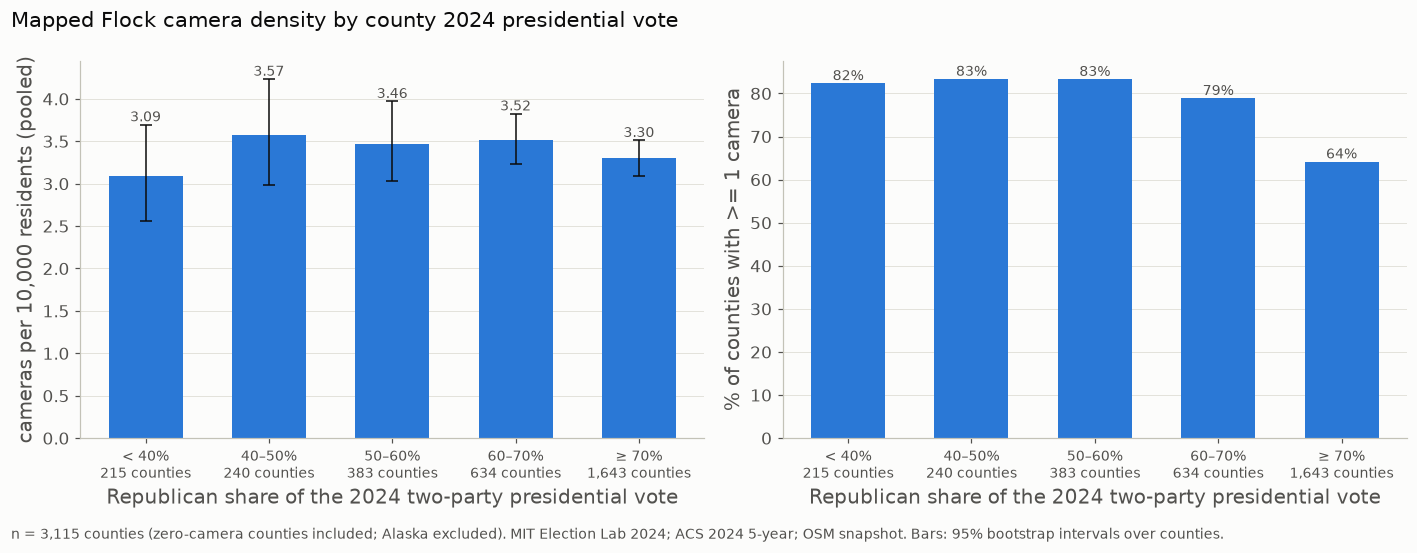

vote_cat,counties,population,cameras,pooled_per_10k,ci_lo,ci_hi,share_with_camera,share_atlas_flock
str,i64,i64,i64,f64,f64,f64,f64,f64
"""< 40%""",215,95500326,29553,3.09,2.56,3.7,0.823,0.433
"""40–50%""",240,73177808,26120,3.57,2.98,4.23,0.833,0.45
"""50–60%""",383,69672886,24128,3.46,3.04,3.97,0.833,0.436
"""60–70%""",634,49886398,17551,3.52,3.24,3.82,0.789,0.402
"""≥ 70%""",1643,46169431,15250,3.3,3.1,3.51,0.642,0.254


In [41]:
VOTE_BINS = [40, 50, 60, 70]
VOTE_LABELS = ["< 40%", "40–50%", "50–60%", "60–70%", "≥ 70%"]
ana = ana.with_columns(pl.col("rep_share").cut(VOTE_BINS, labels=VOTE_LABELS, left_closed=True).alias("vote_cat"))

def group_rates(df: pl.DataFrame, by: str, labels: list[str]) -> pl.DataFrame:
    rows = []
    for lab in labels:
        g = df.filter(pl.col(by) == lab)
        est, lo, hi = pooled_rate(g["cameras"].to_numpy(), g["population"].to_numpy())
        rows.append({by: lab, "counties": g.height, "population": int(g["population"].sum()), "cameras": int(g["cameras"].sum()),
                     "pooled_per_10k": est, "ci_lo": lo, "ci_hi": hi, "share_with_camera": (g["cameras"] > 0).mean(),
                     "share_atlas_flock": g["atlas_flock"].mean()})
    return pl.DataFrame(rows)

v7tab = group_rates(ana, "vote_cat", VOTE_LABELS)

def v7_figure(tab: pl.DataFrame):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
    x = np.arange(len(tab))
    names = [f"{c}\n{n:,} counties" for c, n in zip(tab["vote_cat"], tab["counties"])]
    a1.bar(x, tab["pooled_per_10k"], color=BLUE, width=0.6, zorder=2)
    a1.errorbar(x, tab["pooled_per_10k"], yerr=[tab["pooled_per_10k"] - tab["ci_lo"], tab["ci_hi"] - tab["pooled_per_10k"]],
                fmt="none", ecolor=INK, capsize=4, linewidth=1, zorder=3)
    a1.set_ylabel("cameras per 10,000 residents (pooled)")
    a2.bar(x, tab["share_with_camera"] * 100, color=BLUE, width=0.6, zorder=2)
    a2.set_ylabel("% of counties with >= 1 camera")
    for i, r in enumerate(tab.iter_rows(named=True)):
        a1.text(x[i], r["ci_hi"], f"{r['pooled_per_10k']:.2f}", ha="center", va="bottom", fontsize=9, color=MUTED)
        a2.text(x[i], r["share_with_camera"] * 100, f"{r['share_with_camera']:.0%}", ha="center", va="bottom", fontsize=9, color=MUTED)
    for a in (a1, a2):
        a.set_xticks(x, names, fontsize=9); a.set_xlabel("Republican share of the 2024 two-party presidential vote"); a.grid(axis="x", visible=False)
    fig.suptitle("Mapped Flock camera density by county 2024 presidential vote", x=0.01, ha="left", fontsize=14)
    fig.text(0.01, -0.02, f"n = {tab['counties'].sum():,} counties (zero-camera counties included; Alaska excluded). "
             "MIT Election Lab 2024; ACS 2024 5-year; OSM snapshot. Bars: 95% bootstrap intervals over counties.", color=MUTED, fontsize=9)
    fig.tight_layout()
    return fig

fig = v7_figure(v7tab)
plt.show()
assert v7tab["counties"].sum() == ana.height and v7tab["cameras"].sum() == int(ana["cameras"].sum())
v7tab.with_columns(pl.col(c).round(2) for c in ["pooled_per_10k", "ci_lo", "ci_hi"]).with_columns(
    pl.col("share_with_camera", "share_atlas_flock").round(3))

In [42]:
# Robustness 1: the same categories within one state at a time would leave few counties per cell, so instead rank
# counties by vote share within their own state and pool by within-state quintile.
wq = ana.with_columns(pl.col("rep_share").rank("ordinal").over("state").alias("_r"), pl.len().over("state").alias("_n")) \
        .with_columns(((pl.col("_r") - 1) * 5 // pl.col("_n") + 1).alias("within_state_R_quintile"))
print("within-state quintiles of Republican share (1 = most Democratic county in its state)")
print(wq.group_by("within_state_R_quintile").agg(pl.len().alias("counties"), pl.col("cameras").sum(),
      (pl.col("cameras").sum() / pl.col("population").sum() * 1e4).round(2).alias("pooled_per_10k"),
      (pl.col("cameras") > 0).mean().round(3).alias("share_with_camera")).sort("within_state_R_quintile"))

# Robustness 2: vote category is tied to county size. Pool within population-size bands.
size = ana.with_columns(pl.col("population").cut([25_000, 100_000, 500_000], labels=["< 25k", "25k–100k", "100k–500k", "≥ 500k"]).alias("size"))
print("\npooled cameras per 10k by county size (rows) and vote category (columns)")
(size.group_by("size", "vote_cat").agg((pl.col("cameras").sum() / pl.col("population").sum() * 1e4).round(2).alias("r"))
     .pivot(on="vote_cat", index="size", values="r").select("size", *VOTE_LABELS).sort("size"))

within-state quintiles of Republican share (1 = most Democratic county in its state)
shape: (5, 5)
┌─────────────────────────┬──────────┬─────────┬────────────────┬───────────────────┐
│ within_state_R_quintile ┆ counties ┆ cameras ┆ pooled_per_10k ┆ share_with_camera │
│ ---                     ┆ ---      ┆ ---     ┆ ---            ┆ ---               │
│ u32                     ┆ u32      ┆ u32     ┆ f64            ┆ f64               │
╞═════════════════════════╪══════════╪═════════╪════════════════╪═══════════════════╡
│ 1                       ┆ 642      ┆ 64576   ┆ 3.62           ┆ 0.844             │
│ 2                       ┆ 624      ┆ 20299   ┆ 3.05           ┆ 0.792             │
│ 3                       ┆ 624      ┆ 16430   ┆ 3.58           ┆ 0.736             │
│ 4                       ┆ 624      ┆ 7264    ┆ 2.68           ┆ 0.657             │
│ 5                       ┆ 601      ┆ 4033    ┆ 2.46           ┆ 0.574             │
└─────────────────────────┴──────────┴───

size,< 40%,40–50%,50–60%,60–70%,≥ 70%
enum,f64,f64,f64,f64,f64
"""< 25k""",3.64,2.63,2.96,2.86,2.77
"""25k–100k""",3.65,2.66,2.86,3.31,3.28
"""100k–500k""",3.37,3.11,3.64,3.73,3.9
"""≥ 500k""",3.02,3.82,3.47,3.29,3.49


**Interpretation.** **Camera density does not differ by how a county voted.** Pooled over residents, every category
sits between 3.1 and 3.6 cameras per 10,000, and the intervals overlap heavily. The one visible difference is in the
right panel: only **64% of the most Republican counties (≥ 70%) have any mapped camera, against 79–83%** elsewhere.

That gap is about **county size, not politics**. The ≥ 70% group is mostly very small rural counties (1,643 counties
holding 14% of residents), and small counties are less likely to have any camera at all. Within county-size bands there
is no consistent direction: in counties under 25,000 people the most Democratic group is highest (3.64 vs 2.6–3.0),
while among counties of 100,000–500,000 density rises with Republican share (3.37 → 3.90). Ranking counties within
their own state shows more cameras in each state's most Democratic counties (3.62 vs 2.46 per 10,000). But those are
usually the state's largest counties, so this does not separate party from size. V8 tests it directly.

**Limitation.** County vote share is a crude summary of local politics; cameras are bought by cities, counties,
sheriffs, HOAs and retailers, not by counties as a whole.

### V8. County camera density vs. Republican vote share (scatter + adjusted association)

Each dot is a county (area ∝ population). The y-axis is log scale, so counties with no mapped camera are drawn on a
separate strip at the bottom. The orange line is the pooled rate in 5-point vote-share bins.

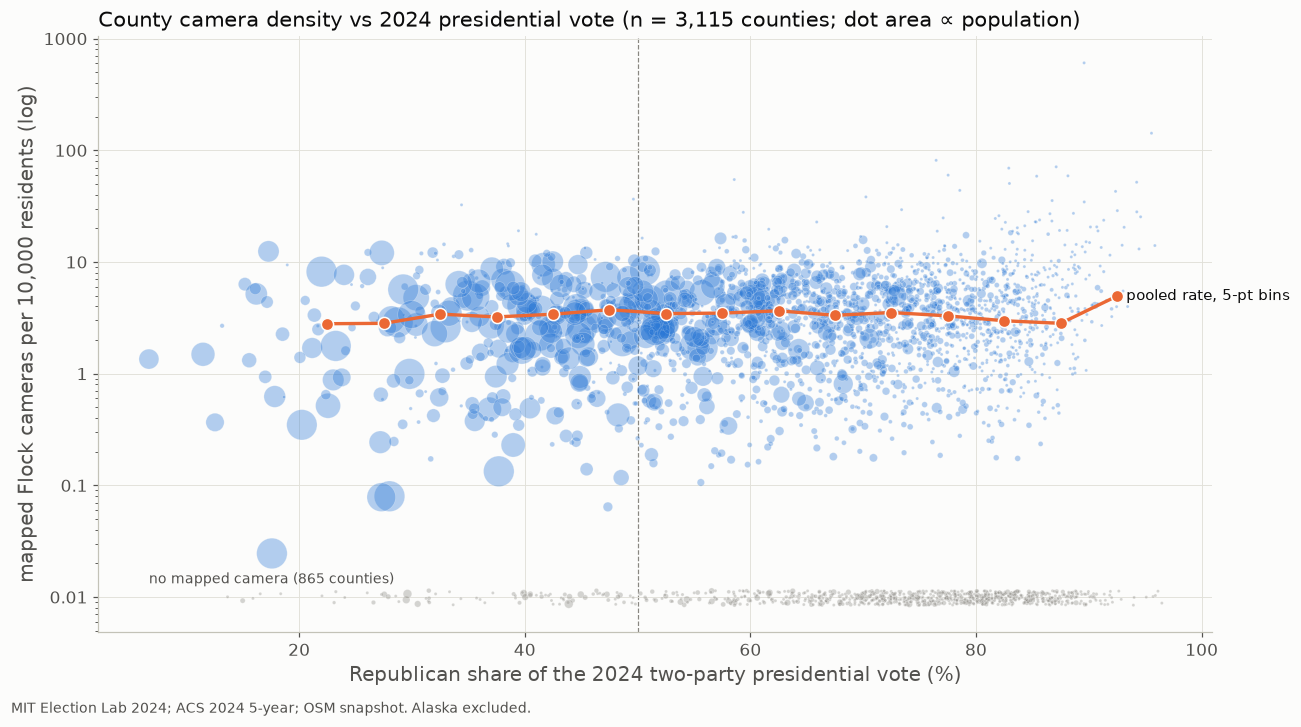

pooled rate by 5-pt bin: [(22.5, 2.8, 22), (27.5, 2.82, 35), (32.5, 3.41, 54), (37.5, 3.22, 83), (42.5, 3.4, 113), (47.5, 3.74, 127), (52.5, 3.45, 172), (57.5, 3.48, 211), (62.5, 3.65, 294), (67.5, 3.33, 340), (72.5, 3.52, 404), (77.5, 3.29, 445), (82.5, 2.97, 469), (87.5, 2.82, 263), (92.5, 4.95, 55)]


In [43]:
def v8_scatter(df: pl.DataFrame):
    fig, ax = plt.subplots(figsize=(12, 6.5))
    pos, zero = df.filter(pl.col("cameras") > 0), df.filter(pl.col("cameras") == 0)
    floor = pos["cameras_per_10k"].min() / 2.5
    rng = np.random.default_rng(418)
    s = lambda d: np.clip(d["population"].to_numpy() / 4000, 4, 400)
    ax.scatter(pos["rep_share"], pos["cameras_per_10k"], s=s(pos), color=BLUE, alpha=0.35, edgecolor="#fcfcfb", linewidth=0.4, zorder=2)
    ax.scatter(zero["rep_share"], floor * np.exp(rng.uniform(-0.15, 0.15, zero.height)), s=s(zero), color=GREY, alpha=0.35,
               edgecolor="#fcfcfb", linewidth=0.4, zorder=2)
    ax.text(df["rep_share"].min(), floor * 1.35, f"no mapped camera ({zero.height:,} counties)", color=MUTED, fontsize=9)
    bins = df.with_columns((pl.col("rep_share") // 5 * 5 + 2.5).alias("mid")).group_by("mid").agg(
        (pl.col("cameras").sum() / pl.col("population").sum() * 1e4).alias("r"), pl.len().alias("n")).filter(pl.col("n") >= 20).sort("mid")
    ax.plot(bins["mid"], bins["r"], color=ORANGE, linewidth=2.2, marker="o", markersize=8, markeredgecolor="#fcfcfb", zorder=4)
    ax.annotate("pooled rate, 5-pt bins", (bins["mid"][-1], bins["r"][-1]), xytext=(6, 0), textcoords="offset points",
                color=INK, fontsize=10, va="center")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.axvline(50, color=GREY, linewidth=0.8, linestyle="--", zorder=1)
    ax.set_xlabel("Republican share of the 2024 two-party presidential vote (%)")
    ax.set_ylabel("mapped Flock cameras per 10,000 residents (log)")
    ax.set_title(f"County camera density vs 2024 presidential vote (n = {df.height:,} counties; dot area ∝ population)", loc="left")
    fig.text(0.01, -0.01, "MIT Election Lab 2024; ACS 2024 5-year; OSM snapshot. Alaska excluded.", color=MUTED, fontsize=9)
    fig.tight_layout()
    return fig, bins

fig, v8bins = v8_scatter(ana)
plt.show()
print("pooled rate by 5-pt bin:", [(m, round(r, 2), n) for m, r, n in v8bins.iter_rows()])

In [44]:
# --- how strong is the association, and does it survive controls? -------------------------------------------------
rho_all = stats.spearmanr(ana["rep_share"], ana["cameras_per_10k"])
rho_pos = stats.spearmanr(ana.filter(pl.col("cameras") > 0)["rep_share"], ana.filter(pl.col("cameras") > 0)["cameras_per_10k"])
# within-state: rank both variables inside each state, then correlate the within-state ranks
ws = ana.filter(pl.len().over("state") >= 5).with_columns(
    ((pl.col("rep_share").rank() - 1) / (pl.len() - 1)).over("state").alias("rx"),
    ((pl.col("cameras_per_10k").rank() - 1) / (pl.len() - 1)).over("state").alias("ry"))
rho_ws = stats.pearsonr(ws["rx"], ws["ry"])
print(f"Spearman rho, R share vs cameras per 10k, all counties     : {rho_all.statistic:+.3f} (p = {rho_all.pvalue:.1g}, n = {ana.height:,})")
print(f"  counties with >= 1 camera only                           : {rho_pos.statistic:+.3f} (n = {ana.filter(pl.col('cameras') > 0).height:,})")
print(f"  within-state ranks (states with >= 5 counties)           : {rho_ws.statistic:+.3f} (n = {ws.height:,})")
print(f"Spearman rho, R share vs log population density            : {stats.spearmanr(ana['rep_share'], ana['pop_density']).statistic:+.3f}")
print(f"Spearman rho, R share vs population                        : {stats.spearmanr(ana['rep_share'], ana['population']).statistic:+.3f}")

def ols(y, X, names):
    """OLS with HC1 robust standard errors (numpy only; statsmodels is not installed)."""
    X = np.column_stack([np.ones(len(y)), X])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ beta
    n, k = X.shape
    XtXi = np.linalg.pinv(X.T @ X)
    V = XtXi @ (X.T * e ** 2) @ X @ XtXi * n / (n - k)
    se = np.sqrt(np.diag(V))
    return pl.DataFrame({"term": ["const", *names], "coef": beta, "se": se, "ci_lo": beta - 1.96 * se, "ci_hi": beta + 1.96 * se}).slice(1, len(names))

m = ana.drop_nulls(["pct_nh_white", "income_pw", "pop_density"]).filter(
    pl.col("pop_density") > 0, *[pl.col(c).is_finite() for c in ["pct_nh_white", "income_pw", "pop_density", "rep_share"]])
y = np.log1p(m["cameras_per_10k"].to_numpy())
x_vote = (m["rep_share"].to_numpy() - 50) / 10                       # per 10 points of Republican share
ctrl = np.column_stack([np.log(m["pop_density"].to_numpy()), m["pct_nh_white"].to_numpy() / 10, np.log(m["income_pw"].to_numpy())])
fe = pd.get_dummies(m["state"].to_pandas(), drop_first=True).to_numpy(float)
models = {
    "A: vote only": (x_vote[:, None], ["R share (+10 pts)"]),
    "B: + state fixed effects": (np.column_stack([x_vote, fe]), ["R share (+10 pts)"] + [f"fe{i}" for i in range(fe.shape[1])]),
    "C: + density, % white, income": (np.column_stack([x_vote, ctrl, fe]),
                                      ["R share (+10 pts)", "log pop density", "% NH white (+10 pts)", "log income"] + [f"fe{i}" for i in range(fe.shape[1])]),
}
res = pl.concat([ols(y, X, names).filter(~pl.col("term").str.starts_with("fe")).with_columns(pl.lit(k).alias("model"))
                 for k, (X, names) in models.items()])
print(f"\noutcome: log(1 + cameras per 10k), n = {m.height:,} counties; coefficients with 95% robust CIs")
res.select("model", "term", *[pl.col(c).round(3) for c in ["coef", "se", "ci_lo", "ci_hi"]])

Spearman rho, R share vs cameras per 10k, all counties     : -0.095 (p = 9e-08, n = 3,115)
  counties with >= 1 camera only                           : +0.130 (n = 2,250)
  within-state ranks (states with >= 5 counties)           : -0.180 (n = 3,104)
Spearman rho, R share vs log population density            : -0.491
Spearman rho, R share vs population                        : -0.529

outcome: log(1 + cameras per 10k), n = 3,114 counties; coefficients with 95% robust CIs


model,term,coef,se,ci_lo,ci_hi
str,str,f64,f64,f64,f64
"""A: vote only""","""R share (+10 pts)""",-0.028,0.01,-0.048,-0.007
"""B: + state fixed effects""","""R share (+10 pts)""",-0.07,0.011,-0.091,-0.048
"""C: + density, % white, income""","""R share (+10 pts)""",0.007,0.018,-0.029,0.042
"""C: + density, % white, income""","""log pop density""",0.02,0.018,-0.015,0.056
"""C: + density, % white, income""","""% NH white (+10 pts)""",-0.056,0.014,-0.084,-0.027
"""C: + density, % white, income""","""log income""",0.658,0.081,0.499,0.818


**Interpretation.** The scatter shows no trend: the orange pooled-rate line stays between about 2.8 and 3.7 cameras per
10,000 across almost the whole range (the last bin, 90%+ R, is 55 small counties). The numbers agree:

- The raw rank correlation is **weak and slightly negative** (ρ = −0.10 across all counties; −0.18 within states).
  Among counties that have at least one camera it is slightly *positive* (+0.13). The negative overall value comes from
  the zero-camera counties, which are small and Republican.
- Republican share is **strongly tied to county size** (ρ = −0.53 with population, −0.49 with density), so the raw
  numbers mix politics with size.
- In a regression of log(1 + cameras per 10k) with state fixed effects, the vote coefficient is small and negative
  (−0.07 per 10 points). **Adding density, % non-Hispanic white and income makes it vanish: +0.007 per 10 points
  (95% CI −0.03 to +0.04).**
- In that model the variables that do matter are **county income** (richer counties have more cameras per resident:
  +0.66 per log-unit of income) and **% non-Hispanic white** (−0.06 per 10 points, consistent with V5). Density adds
  nothing once these are in.

**Bottom line for Q3:** **no association between county voting and mapped Flock camera density once county size,
wealth, racial composition and state are accounted for.** The small raw differences are explained by those factors.

**Limitation.** Cross-sectional, county-level, observational. Income and racial composition are themselves correlated
with vote, so "controlling" for them asks a narrower question (same income and composition, different vote). The
outcome is mapped cameras, so uneven mapping effort remains a possible confounder.

### V9. Flock adoption evidence by county vote *(proxy — procurement data does not exist)*

The milestone plan wanted municipal **procurement decisions** (council votes, contracts). No such dataset exists in the
repo or publicly in a usable form, so V9 uses the best available proxy and labels it as such: the share of counties
where the **Atlas of Surveillance** records at least one agency using Flock ALPRs, shown next to the share of counties
with at least one OSM-mapped Flock camera. The two sources are independent (news and public records vs volunteer
mapping), so agreement between them is informative; neither is a procurement record.

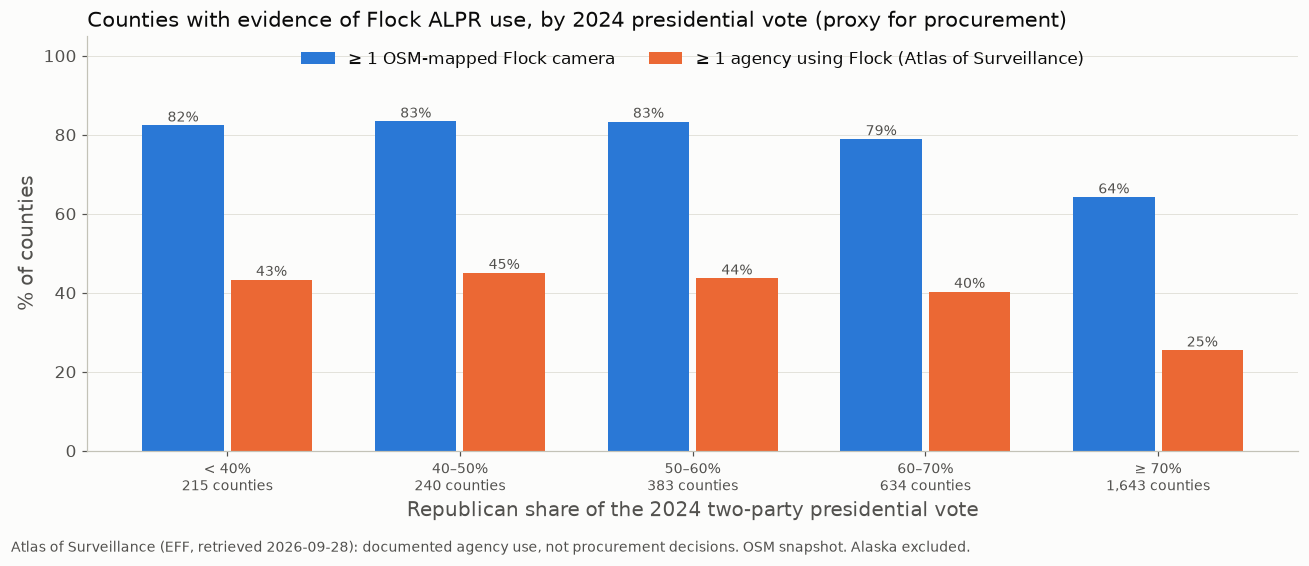

agreement between the two sources (counties):
shape: (4, 3)
┌────────────┬─────────────┬──────┐
│ osm_camera ┆ atlas_flock ┆ len  │
│ ---        ┆ ---         ┆ ---  │
│ bool       ┆ bool        ┆ u32  │
╞════════════╪═════════════╪══════╡
│ false      ┆ false       ┆ 858  │
│ false      ┆ true        ┆ 7    │
│ true       ┆ false       ┆ 1217 │
│ true       ┆ true        ┆ 1033 │
└────────────┴─────────────┴──────┘
Atlas Flock share among counties WITH an OSM camera   : 45.9%
Atlas Flock share among counties WITHOUT an OSM camera: 0.8%


size,< 40%,40–50%,50–60%,60–70%,≥ 70%
enum,f64,f64,f64,f64,f64
"""< 25k""",0.077,0.098,0.162,0.148,0.124
"""25k–100k""",0.268,0.309,0.355,0.464,0.459
"""100k–500k""",0.629,0.59,0.684,0.681,0.706
"""≥ 500k""",0.65,0.848,0.759,0.75,1.0


In [45]:
def v9_figure(tab: pl.DataFrame):
    fig, ax = plt.subplots(figsize=(12, 5))
    x, w = np.arange(len(tab)), 0.38
    series = [("share_with_camera", "≥ 1 OSM-mapped Flock camera", BLUE), ("share_atlas_flock", "≥ 1 agency using Flock (Atlas of Surveillance)", ORANGE)]
    for j, (col, lab, colr) in enumerate(series):
        xs = x + (j - 0.5) * w
        ax.bar(xs, tab[col] * 100, width=w - 0.03, color=colr, label=lab, zorder=2)
        for xi, v in zip(xs, tab[col]):
            ax.text(xi, v * 100 + 1.0, f"{v:.0%}", ha="center", fontsize=9, color=MUTED)
    ax.set_xticks(x, [f"{c}\n{n:,} counties" for c, n in zip(tab["vote_cat"], tab["counties"])], fontsize=9)
    ax.set_xlabel("Republican share of the 2024 two-party presidential vote"); ax.set_ylabel("% of counties")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 105)
    ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
    ax.set_title("Counties with evidence of Flock ALPR use, by 2024 presidential vote (proxy for procurement)", loc="left")
    fig.text(0.01, -0.02, "Atlas of Surveillance (EFF, retrieved 2026-09-28): documented agency use, not procurement decisions. "
             "OSM snapshot. Alaska excluded.", color=MUTED, fontsize=9)
    fig.tight_layout()
    return fig

fig = v9_figure(v7tab)
plt.show()
both_src = pl.DataFrame({"osm_camera": ana["cameras"] > 0, "atlas_flock": ana["atlas_flock"]}).group_by("osm_camera", "atlas_flock").len().sort("osm_camera", "atlas_flock")
print("agreement between the two sources (counties):"); print(both_src)
print("Atlas Flock share among counties WITH an OSM camera   :", f"{ana.filter(pl.col('cameras') > 0)['atlas_flock'].mean():.1%}")
print("Atlas Flock share among counties WITHOUT an OSM camera:", f"{ana.filter(pl.col('cameras') == 0)['atlas_flock'].mean():.1%}")

# Does the vote pattern in the Atlas proxy survive county size? Share with an Atlas Flock record, size band x vote category.
(size.group_by("size", "vote_cat").agg(pl.col("atlas_flock").mean().round(3).alias("s"))
     .pivot(on="vote_cat", index="size", values="s").select("size", *VOTE_LABELS).sort("size"))

**Interpretation.** The milestone plan's V9 needed municipal procurement decisions, which do not exist as a dataset, so
this is a **labelled proxy**. Two things stand out.

- **The two sources agree.** Almost every county with an Atlas Flock record also has OSM-mapped cameras: only 7 of
  1,040 do not. The Atlas is clearly the less complete source; 1,217 counties have mapped cameras but no Atlas record.
  Agreement between independent sources (news/public records vs volunteer mapping) supports the OSM data as a signal of
  real deployment, without making it a count of installed cameras.
- **The vote pattern is again a size effect.** The Atlas share is 40–45% up to 70% Republican and drops to 25% in the
  ≥ 70% group. But within size bands it does **not** fall with Republican share, and it mostly *rises*: 27% → 46% among
  counties of 25,000–100,000 people and 63% → 71% among those of 100,000–500,000. Small rural counties are simply less
  likely to have a documented agency, and the Atlas relies on reporting, which is thinner there.

**Limitation.** The Atlas records documented use by an agency, not a council vote, contract or date. It depends on news
coverage and records requests, so it under-represents small places. This proxy **cannot answer the procurement
question**; it only shows where adoption is documented.

## M9. Final QA

Goal: every figure reconciles to the source data, every exclusion is counted, and every claim in the interpretations
can be traced to a printed number. The cell below re-checks the nine visuals together.

In [46]:
tract_total = int(tract["cameras"].sum())
qa = [
    ("V1 map", f"{s1['plotted']:,} plotted", s1["plotted"] == flock.height and s1["not_in_any_panel"] == 0,
     "all Flock cameras in a panel (lower 48, AK, HI, PR+VI)"),
    ("V2 growth", f"{s2['final_cumulative']:,} dated", s2["nondecreasing"] and s2["final_cumulative"] == hist.filter("is_flock").height,
     "history cohort, 0 undated; 706 newer snapshot cameras have no date"),
    ("V3 by state", f"{int(v3['cameras'].sum()):,}", int(v3["cameras"].sum()) == flock.height, "0 unassigned"),
    ("V4 income", f"{int(v4tab['cameras'].sum()):,} in quintiles",
     int(v4tab["cameras"].sum() + excl["cameras"].sum() + no_acs["cameras"].sum()) == tract_total,
     f"+ {int(excl['cameras'].sum()):,} no income/0 residents + {int(no_acs['cameras'].sum())} no ACS = tract total {tract_total:,}; "
     f"{flock.height - tract_total} PR/USVI cameras have no tract"),
    ("V5 poverty", f"{int(v5_pov['cameras'].sum()):,}", int(v5_pov["cameras"].sum()) == int(elig.drop_nulls("pct_poverty")["cameras"].sum()),
     "same eligible tracts as V4"),
    ("V5 race", f"{int(v5_race['cameras'].sum()):,}", int(v5_race["cameras"].sum()) == int(elig.drop_nulls("pct_nh_white")["cameras"].sum()),
     "same eligible tracts as V4"),
    ("V6 Chicago map", f"{s6['cameras_plotted']:,}", s6["cameras_plotted"] == s6["cameras_in_tract_table_for_area"], "plotted = tract table for 9 counties"),
    ("V7 vote categories", f"{int(v7tab['cameras'].sum()):,}", int(v7tab["cameras"].sum()) == int(ana["cameras"].sum()) and v7tab["counties"].sum() == ana.height,
     f"+ {int(county.filter(~pl.col('has_vote'))['cameras'].sum())} cameras in counties without a vote (AK, territories) "
     f"= {int(county['cameras'].sum()):,}"),
    ("V8 scatter/model", f"{ana.height:,} counties", ana.height == v7tab["counties"].sum(), f"model n = {m.height:,} (complete controls)"),
    ("V9 Atlas proxy", f"{int(ana['atlas_flock'].sum()):,} counties", True, "proxy only; labelled on the chart"),
]
qa = pl.DataFrame(qa, schema=["visual", "n", "reconciles", "note"], orient="row")
assert qa["reconciles"].all(), qa.filter(~pl.col("reconciles"))
assert int(county["cameras"].sum()) == flock.height
print("all reconciliation checks passed")
qa

all reconciliation checks passed


visual,n,reconciles,note
str,str,bool,str
"""V1 map""","""112,823 plotted""",true,"""all Flock cameras in a panel (lower 48, AK, HI, PR+VI)"""
"""V2 growth""","""112,522 dated""",true,"""history cohort, 0 undated; 706 newer snapshot cameras have no date"""
"""V3 by state""","""112,823""",true,"""0 unassigned"""
"""V4 income""","""111,382 in quintiles""",true,"""+ 1,235 no income/0 residents + 2 no ACS = tract total 112,619; 204 PR…"
"""V5 poverty""","""111,382""",true,"""same eligible tracts as V4"""
"""V5 race""","""111,382""",true,"""same eligible tracts as V4"""
"""V6 Chicago map""","""3,387""",true,"""plotted = tract table for 9 counties"""
"""V7 vote categories""","""112,602""",true,"""+ 221 cameras in counties without a vote (AK, territories) = 112,823"""
"""V8 scatter/model""","""3,115 counties""",true,"""model n = 3,114 (complete controls)"""


In [47]:
# Inputs used, for the write-up.
used = ["locations", "history", "acs_pop", "acs_income", "acs_poverty", "acs_race", "elections", "counties", "tracts_2024",
        "chicago_city", "chicago_wards", "chicago_ward_income", "ff_state", "atlas"]
pl.DataFrame({"input": used, "path": [str(P[k].relative_to(ROOT)).replace("\\", "/") for k in used]}) \
  .vstack(pl.DataFrame({"input": ["ct_2017_tracts"], "path": ["data/external/census_boundaries/2017/tl_2017_09_tract.zip"]}))

input,path
str,str
"""locations""","""data/raw/flock_osm/osm_flock_us_locations_2026-10-30.csv"""
"""history""","""data/raw/flock_osm/flock_us_historical_2026-10-30.csv"""
"""acs_pop""","""data/raw/census/population/2024/ACSDT5Y2024.B01003-Data.csv"""
"""acs_income""","""data/raw/census/median_household_income/2024/ACSDT5Y2024.B19013-Data.c…"
"""acs_poverty""","""data/raw/census/poverty/2024/ACSST5Y2024.S1701-Data.csv"""
"""acs_race""","""data/raw/census/race_ethnicity/2024/ACSDT5Y2024.B03002-Data.csv"""
"""elections""","""data/raw/elections/presidential/countypres_2000-2024.csv"""
"""counties""","""data/external/census_boundaries/counties/tl_2024_us_county.zip"""
"""tracts_2024""","""data/external/census_boundaries/2024"""


**What stands out (QA).** Every visual reconciles: V1 and V3 to the 112,823-camera snapshot; V2 to the 112,522 dated
history cameras; V4–V5 to the tract table (plus counted exclusions and the 204 PR/USVI cameras that have no tract); V6
to the Chicago-area tract counts; V7–V8 to the 3,115-county analysis set (plus 221 cameras in places with no
presidential vote). The V8 model uses 3,114 counties (one lacks controls).

### Summary of findings (all associations with *mapped* cameras; none causal)

| Question | Finding | Strength |
|---|---|---|
| Q1 Where | Cameras follow population (state ρ = 0.89); per capita, Georgia 85 per 100k vs New England ≈ 1–3 | **Strong** |
| Q1 Growth | Mapping grew in bursts (Nov 2025 – Jan 2026, Jul–Aug 2026): campaigns and re-tagging, not installations | Strong (descriptive) |
| Q1 Check | State totals agree with Finding Flock (ρ = 0.98); counties agree with the Atlas of Surveillance | Strong |
| Q2 Income | Flat nationally (tract ρ = −0.03); the Chicago-area gap is city vs suburbs | **None** |
| Q2 Poverty | Very slight rise with poverty (3.2 → 3.6 per 10k) | Negligible |
| Q2 Race | Whitest tracts have fewer cameras (2.3 vs 4.1 per 10k); about half is between states; also negative at county level | **Modest** |
| Q3 Vote | Flat by vote category; the small raw differences disappear after size, income, race and state | **None** |
| Q3 Procurement | No procurement data; the Atlas proxy's vote pattern is a county-size effect | Not answerable |

### Limitations that apply throughout

- **Mapped ≠ installed.** OSM coverage depends on volunteers; dense areas may reflect active mappers.
- **Dates are mapping dates.** V2 is mapping activity, starting in Nov 2024 for tagging reasons.
- **Strict tag rule.** Flock cameras tagged only via `brand`/`operator` are not counted (dev2 estimated ~4%, uneven by
  state); not re-checkable from repo data.
- **Not in the repo:** crime data (V5 replaced), procurement data (V9 proxy), PR tract boundaries, OSM history cache.
- **Observational and cross-sectional.** No result here says why cameras are where they are.